# Digital Evidence Integrity & Fraud Detection in Consumer Complaints
Priyanka S (23MIA1032) , Kavya N (23MIA1125)

## Installing required libraries

In [1]:
!pip install -q pandas requests pillow scikit-learn networkx matplotlib pyarrow


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: C:\Users\PRIYANKA\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


## Importing libraries

In [2]:
import os
import re
import json
import warnings
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt
import networkx as nx

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.neighbors import NearestNeighbors
from sklearn.ensemble import IsolationForest
from sklearn.preprocessing import StandardScaler

from PIL import Image

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 100)
pd.set_option("display.max_colwidth", 160)

## Creating project folders

In [3]:
BASE_DIR = Path("/content/amazon_forensic_project")
DATA_DIR = BASE_DIR / "data"
IMAGE_DIR = BASE_DIR / "images"
OUTPUT_DIR = BASE_DIR / "outputs"

DATA_DIR.mkdir(parents=True, exist_ok=True)
IMAGE_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print(BASE_DIR)

\content\amazon_forensic_project


## Setting analysis parameters

In [4]:
CATEGORY = "Electronics"
MAX_REVIEWS = 60000
MIN_REVIEW_LENGTH = 20
NEGATIVE_RATINGS = [1, 2]
RANDOM_STATE = 42
IMAGE_DOWNLOAD_LIMIT = 300
MAX_IMAGES_PER_REVIEW = 3
TEXT_SIMILARITY_LIMIT = 20000

## Defining the verified Amazon Reviews 2023 review source

In [5]:
REVIEW_URL = (
    "https://huggingface.co/datasets/"
    "McAuley-Lab/Amazon-Reviews-2023/resolve/main/"
    "raw/review_categories/Electronics.jsonl"
)

print(REVIEW_URL)

https://huggingface.co/datasets/McAuley-Lab/Amazon-Reviews-2023/resolve/main/raw/review_categories/Electronics.jsonl


## Testing access to the review source

In [6]:
response = requests.get(
    REVIEW_URL,
    stream=True,
    timeout=30
)

print("Status code:", response.status_code)
print("Final URL:", response.url)
print("Content type:", response.headers.get("content-type"))

response.raise_for_status()
response.close()

Status code: 200
Final URL: https://us.aws.cdn.hf.co/xet-bridge-us/65af4645d0a5cc99d51642da/28866377eb7aec134fa8b5028e64a9d5de9960a671ef0babc5e0e177e1a96bc1?user_id=public&xip=FP1iWAeRaIk&response-content-disposition=inline%3B+filename*%3DUTF-8%27%27Electronics.jsonl%3B+filename%3D%22Electronics.jsonl%22%3B&X-Xet-Cas-Uid=public&Expires=1793296850&Policy=eyJTdGF0ZW1lbnQiOlt7IlJlc291cmNlIjoiaHR0cHM6Ly91cy5hd3MuY2RuLmhmLmNvL3hldC1icmlkZ2UtdXMvNjVhZjQ2NDVkMGE1Y2M5OWQ1MTY0MmRhLzI4ODY2Mzc3ZWI3YWVjMTM0ZmE4YjUwMjhlNjRhOWQ1ZGU5OTYwYTY3MWVmMGJhYmM1ZTBlMTc3ZTFhOTZiYzFcXD91c2VyX2lkPXB1YmxpYyZ4aXA9RlAxaVdBZVJhSWsmcmVzcG9uc2UtY29udGVudC1kaXNwb3NpdGlvbj1pbmxpbmUlM0IrZmlsZW5hbWUlMkElM0RVVEYtOCUyNyUyN0VsZWN0cm9uaWNzLmpzb25sJTNCK2ZpbGVuYW1lJTNEJTIyRWxlY3Ryb25pY3MuanNvbmwlMjIlM0ImWC1YZXQtQ2FzLVVpZD1wdWJsaWMiLCJDb25kaXRpb24iOnsiRGF0ZUxlc3NUaGFuIjp7IkVwb2NoVGltZSI6MTc5MzI5Njg1MH19fV19&Signature=MEUCIQDqpV-~0bE9VZOVI30h8efwhSz7ztzAl-cdoyQE2VrZSgIgZixVrR4o7SHItDiGpDLbvgmqdGXVWtEHiKqDFixIvkg_&Key-Pair-Id=01KX

## Streaming negative reviews from the review source

In [7]:
filtered_file = DATA_DIR / "electronics_negative_reviews.jsonl"

if filtered_file.exists():
    filtered_file.unlink()

session = requests.Session()

response = session.get(
    REVIEW_URL,
    stream=True,
    timeout=60
)

response.raise_for_status()

records = []
scanned_lines = 0
collected_reviews = 0

for raw_line in response.iter_lines(decode_unicode=True):

    if not raw_line:
        continue

    scanned_lines += 1

    try:
        row = json.loads(raw_line)
    except json.JSONDecodeError:
        continue

    rating = row.get("rating")
    text = row.get("text") or ""

    if rating in NEGATIVE_RATINGS and len(text.strip()) >= MIN_REVIEW_LENGTH:

        records.append(row)
        collected_reviews += 1

    if scanned_lines % 100000 == 0:
        print(
            "Scanned:",
            scanned_lines,
            "reviews | Collected:",
            collected_reviews
        )

    if collected_reviews >= MAX_REVIEWS:
        break

response.close()

print("Total reviews scanned:", scanned_lines)
print("Total negative reviews collected:", collected_reviews)

Scanned: 100000 reviews | Collected: 11882
Scanned: 200000 reviews | Collected: 24888
Scanned: 300000 reviews | Collected: 37710
Scanned: 400000 reviews | Collected: 51009
Total reviews scanned: 467845
Total negative reviews collected: 60000


## Saving the collected review records locally

In [8]:
with open(filtered_file, "w", encoding="utf-8") as file:

    for row in records:
        file.write(
            json.dumps(
                row,
                ensure_ascii=False
            ) + "\n"
        )

print(filtered_file)

\content\amazon_forensic_project\data\electronics_negative_reviews.jsonl


## Loading the collected review records

In [9]:
records = []

with open(
    filtered_file,
    "r",
    encoding="utf-8"
) as file:

    for line in file:
        records.append(
            json.loads(line)
        )

reviews = pd.DataFrame(records).head(MAX_REVIEWS).copy()

print("Rows:", len(reviews))
print("Columns:", len(reviews.columns))

Rows: 60000
Columns: 10


## Inspecting the collected reviews

In [10]:
reviews.head()

,rating,title,text,images,asin,parent_asin,user_id,timestamp,helpful_vote,verified_purchase
0,1.0,Didn’t work at all lenses loose/broken.,"These didn’t work. Idk if they were damaged in shipping or what, but the lenses were loose or something. I could see half a lens with its edge in the frame ...",[],B07N69T6TM,B07N69T6TM,AFKZENTNBQ7A7V7UXW5JJI6UGRYQ,1592678549731,0,True
1,1.0,Not sure why this has good reviews. My devices had a hard time connecting,This devices brought my wifi network to its knees. Not sure why this has good reviews. My devices had a hard time connecting. And even if my devices weren't...,[],B00L0YLRUW,B00L0YLRUW,AGCI7FAH4GL5FI65HYLKWTMFZ2CQ,1439226089000,0,True
2,1.0,Don’t buy this product,"DO NOT BUY THIS PRODUCT!! The first time I zipped the first pouch, the zipper broke. I tried another one, same thing, zipper broke on the first try. HORRIB...",[],B0776DSP7Y,B0776DSP7Y,AHITBJSS7KYUBVZPX7M2WJCOIVKQ,1526085167886,1,True
3,2.0,Disappointed,Not very accurate in tracking steps taken. Wrist band started coming off after 3 months of use.,[],B00N2BVOUE,B00NWXM5U0,AHITBJSS7KYUBVZPX7M2WJCOIVKQ,1432345739000,0,True
4,2.0,Very Disappointing,Very very slow processor. Disappointing.,[],B00L49X8E6,B00L49X8E6,AHITBJSS7KYUBVZPX7M2WJCOIVKQ,1432345403000,0,True


## Checking the rating distribution

In [11]:
reviews["rating"].value_counts().sort_index()

rating
1.0    38531
2.0    21469
Name: count, dtype: int64

## Inspecting available review fields

In [12]:
reviews.columns.tolist()

['rating',
 'title',
 'text',
 'images',
 'asin',
 'parent_asin',
 'user_id',
 'timestamp',
 'helpful_vote',
 'verified_purchase']

## Creating a standardized review table

In [13]:
standard = reviews.copy()

required_columns = [
    "rating",
    "title",
    "text",
    "images",
    "asin",
    "parent_asin",
    "user_id",
    "timestamp",
    "verified_purchase",
    "helpful_vote"
]

for column in required_columns:

    if column not in standard.columns:
        standard[column] = np.nan

standard["review_id"] = standard.index.astype(str)
standard["user_id"] = standard["user_id"].fillna("unknown_user").astype(str)
standard["parent_asin"] = standard["parent_asin"].fillna("unknown_product").astype(str)
standard["asin"] = standard["asin"].fillna("unknown_asin").astype(str)
standard["title"] = standard["title"].fillna("").astype(str)
standard["text"] = standard["text"].fillna("").astype(str)
standard["rating"] = pd.to_numeric(standard["rating"], errors="coerce")
standard["timestamp"] = pd.to_numeric(standard["timestamp"], errors="coerce")
standard["helpful_vote"] = pd.to_numeric(
    standard["helpful_vote"],
    errors="coerce"
).fillna(0)

standard["text_clean"] = (
    standard["title"] + " " + standard["text"]
).str.replace(
    r"\s+",
    " ",
    regex=True
).str.strip()

standard["review_date"] = pd.to_datetime(
    standard["timestamp"],
    unit="ms",
    errors="coerce"
)

standard["review_year"] = standard["review_date"].dt.year
standard["review_month"] = standard["review_date"].dt.to_period("M").astype(str)
standard["text_length"] = standard["text_clean"].str.len()
standard["word_count"] = standard["text_clean"].str.split().str.len()

standard.head()

,rating,title,text,images,asin,parent_asin,user_id,timestamp,helpful_vote,verified_purchase,review_id,text_clean,review_date,review_year,review_month,text_length,word_count
0,1.0,Didn’t work at all lenses loose/broken.,"These didn’t work. Idk if they were damaged in shipping or what, but the lenses were loose or something. I could see half a lens with its edge in the frame ...",[],B07N69T6TM,B07N69T6TM,AFKZENTNBQ7A7V7UXW5JJI6UGRYQ,1592678549731,0,True,0,"Didn’t work at all lenses loose/broken. These didn’t work. Idk if they were damaged in shipping or what, but the lenses were loose or something. I could see...",2020-06-20 18:42:29.731,2020,2020-06,265,51
1,1.0,Not sure why this has good reviews. My devices had a hard time connecting,This devices brought my wifi network to its knees. Not sure why this has good reviews. My devices had a hard time connecting. And even if my devices weren't...,[],B00L0YLRUW,B00L0YLRUW,AGCI7FAH4GL5FI65HYLKWTMFZ2CQ,1439226089000,0,True,1,Not sure why this has good reviews. My devices had a hard time connecting This devices brought my wifi network to its knees. Not sure why this has good revi...,2015-08-10 17:01:29.000,2015,2015-08,385,70
2,1.0,Don’t buy this product,"DO NOT BUY THIS PRODUCT!! The first time I zipped the first pouch, the zipper broke. I tried another one, same thing, zipper broke on the first try. HORRIB...",[],B0776DSP7Y,B0776DSP7Y,AHITBJSS7KYUBVZPX7M2WJCOIVKQ,1526085167886,1,True,2,"Don’t buy this product DO NOT BUY THIS PRODUCT!! The first time I zipped the first pouch, the zipper broke. I tried another one, same thing, zipper broke on...",2018-05-12 00:32:47.886,2018,2018-05,183,33
3,2.0,Disappointed,Not very accurate in tracking steps taken. Wrist band started coming off after 3 months of use.,[],B00N2BVOUE,B00NWXM5U0,AHITBJSS7KYUBVZPX7M2WJCOIVKQ,1432345739000,0,True,3,Disappointed Not very accurate in tracking steps taken. Wrist band started coming off after 3 months of use.,2015-05-23 01:48:59.000,2015,2015-05,108,18
4,2.0,Very Disappointing,Very very slow processor. Disappointing.,[],B00L49X8E6,B00L49X8E6,AHITBJSS7KYUBVZPX7M2WJCOIVKQ,1432345403000,0,True,4,Very Disappointing Very very slow processor. Disappointing.,2015-05-23 01:43:23.000,2015,2015-05,59,7


## Extracting review image URLs

In [14]:
def extract_image_urls(value):

    urls = []

    if isinstance(value, list):

        for item in value:

            if isinstance(item, str):
                urls.append(item)

            elif isinstance(item, dict):

                for key in [
                    "large_image_url",
                    "medium_image_url",
                    "small_image_url",
                    "url",
                    "large",
                    "medium",
                    "small"
                ]:

                    if key in item and isinstance(item[key], str):
                        urls.append(item[key])
                        break

    return list(dict.fromkeys(urls))

standard["image_urls"] = standard["images"].apply(
    extract_image_urls
)

standard["has_image"] = standard[
    "image_urls"
].str.len().gt(0)

standard["has_image"].value_counts()

has_image
False    57259
True      2741
Name: count, dtype: int64

## Defining complaint categories

In [15]:
complaint_dictionary = {
    "quality": [
        "broken",
        "defective",
        "poor quality",
        "damaged",
        "stopped working",
        "not working",
        "faulty",
        "dead",
        "cheap"
    ],
    "delivery": [
        "late",
        "delivery",
        "arrived late",
        "not delivered",
        "missing package",
        "shipping",
        "shipment"
    ],
    "seller": [
        "seller",
        "scam",
        "fake",
        "counterfeit",
        "wrong item",
        "fraud"
    ],
    "refund": [
        "refund",
        "return",
        "replacement",
        "money back",
        "customer service"
    ],
    "performance": [
        "slow",
        "overheating",
        "battery",
        "disconnect",
        "crash",
        "lag",
        "does not work",
        "doesn't work"
    ],
    "appearance": [
        "different color",
        "scratched",
        "stain",
        "smell",
        "looks used",
        "not as described"
    ]
}

def detect_categories(text):

    text = str(text).lower()
    found = []

    for category, terms in complaint_dictionary.items():

        if any(
            term in text
            for term in terms
        ):
            found.append(category)

    return found

standard["complaint_categories"] = standard[
    "text_clean"
].apply(
    detect_categories
)

standard["complaint_category_count"] = standard[
    "complaint_categories"
].str.len()

standard["is_complaint_candidate"] = standard[
    "complaint_category_count"
] > 0

standard[[
    "review_id",
    "rating",
    "complaint_categories",
    "is_complaint_candidate"
]].head(10)

,review_id,rating,complaint_categories,is_complaint_candidate
0,0,1.0,"[quality, delivery]",True
1,1,1.0,[performance],True
2,2,1.0,[],False
3,3,2.0,[],False
4,4,2.0,[performance],True
5,5,2.0,[refund],True
6,6,1.0,[],False
7,7,2.0,[],False
8,8,2.0,[],False
9,9,1.0,[],False


## Summarizing complaint categories

In [16]:
complaint_category_counts = Counter()

for categories in standard["complaint_categories"]:

    complaint_category_counts.update(
        categories
    )

complaint_summary = pd.DataFrame(
    complaint_category_counts.items(),
    columns=[
        "complaint_category",
        "review_count"
    ]
).sort_values(
    "review_count",
    ascending=False
)

complaint_summary

,complaint_category,review_count
3,refund,13548
0,quality,12578
2,performance,9465
1,delivery,3690
4,seller,1747
5,appearance,668


## Visualizing complaint category distribution

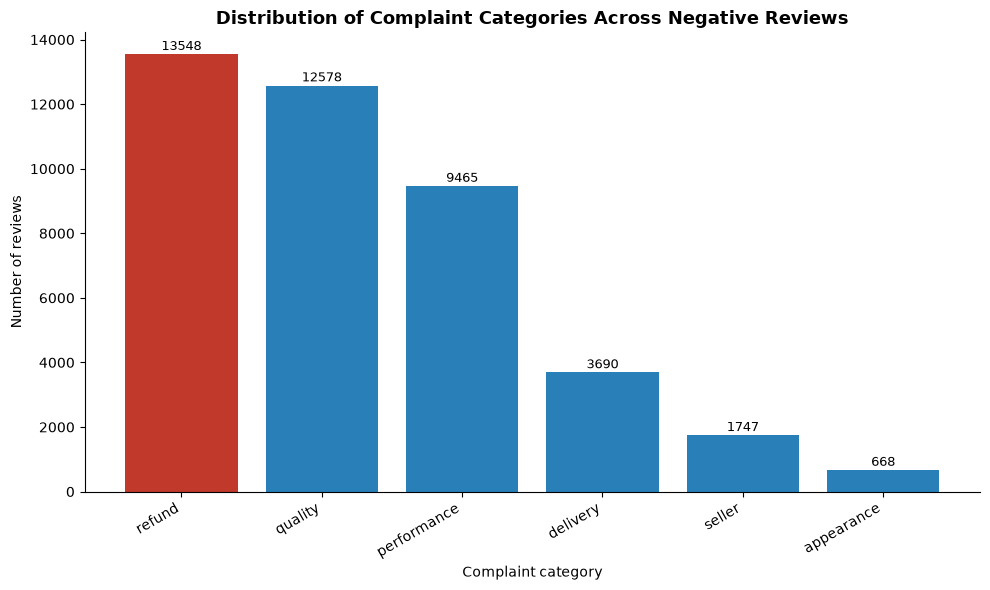

In [17]:
fig, ax = plt.subplots(figsize=(10, 6))

sorted_summary = complaint_summary.sort_values(
    "review_count",
    ascending=False
)

bar_colors = [
    "#c0392b" if value == sorted_summary["review_count"].max() else "#2980b9"
    for value in sorted_summary["review_count"]
]

bars = ax.bar(
    sorted_summary["complaint_category"],
    sorted_summary["review_count"],
    color=bar_colors
)

ax.set_title(
    "Distribution of Complaint Categories Across Negative Reviews",
    fontsize=13,
    fontweight="bold"
)
ax.set_xlabel("Complaint category")
ax.set_ylabel("Number of reviews")
plt.xticks(rotation=30, ha="right")

for bar in bars:
    height = bar.get_height()
    ax.annotate(
        f"{int(height)}",
        xy=(bar.get_x() + bar.get_width() / 2, height),
        xytext=(0, 3),
        textcoords="offset points",
        ha="center",
        fontsize=9
    )

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
plt.tight_layout()
plt.show()

## Calculating population-level statistics

In [18]:
verified_values = standard[
    "verified_purchase"
].astype(str).str.lower()

population_summary = pd.DataFrame({
    "measure": [
        "Total analyzed negative reviews",
        "One-star reviews",
        "Two-star reviews",
        "Complaint candidates",
        "Reviews containing images",
        "Unique reviewers",
        "Unique products",
        "Verified purchases"
    ],
    "value": [
        len(standard),
        int((standard["rating"] == 1).sum()),
        int((standard["rating"] == 2).sum()),
        int(standard["is_complaint_candidate"].sum()),
        int(standard["has_image"].sum()),
        standard["user_id"].nunique(),
        standard["parent_asin"].nunique(),
        int(
            verified_values.isin(
                ["true", "1", "yes"]
            ).sum()
        )
    ]
})

population_summary

,measure,value
0,Total analyzed negative reviews,60000
1,One-star reviews,38531
2,Two-star reviews,21469
3,Complaint candidates,30361
4,Reviews containing images,2741
5,Unique reviewers,31159
6,Unique products,38607
7,Verified purchases,52449


## Building reviewer behavior features

In [19]:
reviewer_features = standard.groupby(
    "user_id"
).agg(
    review_count=("review_id", "count"),
    mean_rating=("rating", "mean"),
    negative_ratio=(
        "rating",
        lambda values: (values <= 2).mean()
    ),
    one_star_ratio=(
        "rating",
        lambda values: (values == 1).mean()
    ),
    complaint_ratio=(
        "is_complaint_candidate",
        "mean"
    ),
    image_ratio=(
        "has_image",
        "mean"
    ),
    product_count=(
        "parent_asin",
        "nunique"
    ),
    mean_text_length=(
        "text_length",
        "mean"
    ),
    helpful_vote_total=(
        "helpful_vote",
        "sum"
    )
).reset_index()

reviewer_features["reviewer_activity_level"] = pd.cut(
    reviewer_features["review_count"],
    bins=[
        -1,
        1,
        5,
        20,
        np.inf
    ],
    labels=[
        "Very low",
        "Low",
        "Moderate",
        "High"
    ]
)

reviewer_features.head()

,user_id,review_count,mean_rating,negative_ratio,one_star_ratio,complaint_ratio,image_ratio,product_count,mean_text_length,helpful_vote_total,reviewer_activity_level
0,AE224GVO7OHTYF26U6ER6BEVIUAQ,1,2.00,1.0,0.00,1.0,0.0,1,339.0,0,Very low
1,AE233NVHTX7SKAY67IS354HLCJHA,4,1.25,1.0,0.75,0.5,0.0,4,365.0,1,Low
2,AE23D3SJBYXFUO7OXEAFXXTU2IPA,1,2.00,1.0,0.00,1.0,0.0,1,2476.0,1,Very low
3,AE23LDQTB7L76AP6E6WPBFVYL5DA,1,2.00,1.0,0.00,1.0,0.0,1,249.0,0,Very low
4,AE23VAK3PVMTVCMUSLXEPC7O3SPQ,1,1.00,1.0,1.00,0.0,0.0,1,1238.0,3,Very low


## Building product behavior features

In [20]:
product_features = standard.groupby(
    "parent_asin"
).agg(
    review_count=("review_id", "count"),
    mean_rating=("rating", "mean"),
    one_star_ratio=(
        "rating",
        lambda values: (values == 1).mean()
    ),
    complaint_ratio=(
        "is_complaint_candidate",
        "mean"
    ),
    image_ratio=(
        "has_image",
        "mean"
    ),
    reviewer_count=(
        "user_id",
        "nunique"
    ),
    mean_text_length=(
        "text_length",
        "mean"
    )
).reset_index()

product_features.head()

,parent_asin,review_count,mean_rating,one_star_ratio,complaint_ratio,image_ratio,reviewer_count,mean_text_length
0,0345803507,4,1.250000,0.750000,0.000000,0.000000,4,319.000000
1,0375505458,1,2.000000,0.000000,0.000000,0.000000,1,1054.000000
2,0544005031,1,2.000000,0.000000,1.000000,0.000000,1,193.000000
3,059449771X,1,2.000000,0.000000,0.000000,0.000000,1,36.000000
4,067167949X,11,1.545455,0.454545,0.181818,0.090909,11,183.272727


## Measuring product rating deviation

In [21]:
standard = standard.merge(
    product_features[[
        "parent_asin",
        "mean_rating",
        "review_count",
        "reviewer_count"
    ]].rename(
        columns={
            "mean_rating": "product_mean_rating",
            "review_count": "product_review_count",
            "reviewer_count": "product_reviewer_count"
        }
    ),
    on="parent_asin",
    how="left"
)

standard["rating_deviation"] = (
    standard["rating"] -
    standard["product_mean_rating"]
).abs()

standard[[
    "review_id",
    "rating",
    "product_mean_rating",
    "rating_deviation"
]].head()

,review_id,rating,product_mean_rating,rating_deviation
0,0,1.0,1.500000,0.500000
1,1,1.0,1.245283,0.245283
2,2,1.0,1.000000,0.000000
3,3,2.0,1.393939,0.606061
4,4,2.0,1.666667,0.333333


## Measuring temporal review concentration

In [22]:
monthly_counts = (
    standard.groupby("review_month")
    .size()
    .reset_index(
        name="review_count"
    )
    .sort_values("review_month")
    .reset_index(drop=True)
)

monthly_counts["rolling_baseline"] = (
    monthly_counts["review_count"]
    .rolling(
        window=3,
        min_periods=1
    )
    .median()
)

monthly_counts["burst_ratio"] = (
    monthly_counts["review_count"] /
    monthly_counts["rolling_baseline"].replace(
        0,
        np.nan
    )
)

monthly_counts["burst_interpretation"] = (
    monthly_counts["burst_ratio"].apply(
        lambda value:
            "Strong concentration compared with recent baseline"
            if value >= 3
            else
            "Moderate concentration compared with recent baseline"
            if value >= 1.5
            else
            "No strong concentration signal"
    )
)

standard = standard.merge(
    monthly_counts[[
        "review_month",
        "burst_ratio",
        "burst_interpretation"
    ]],
    on="review_month",
    how="left"
)

monthly_counts

,review_month,review_count,rolling_baseline,burst_ratio,burst_interpretation
0,1999-12,1,1.0,1.000000,No strong concentration signal
1,2000-07,1,1.0,1.000000,No strong concentration signal
2,2000-12,1,1.0,1.000000,No strong concentration signal
3,2001-03,1,1.0,1.000000,No strong concentration signal
4,2001-05,1,1.0,1.000000,No strong concentration signal
...,...,...,...,...,...
250,2022-11,560,560.0,1.000000,No strong concentration signal
251,2022-12,575,560.0,1.026786,No strong concentration signal
252,2023-01,606,575.0,1.053913,No strong concentration signal
253,2023-02,554,575.0,0.963478,No strong concentration signal


## Visualizing temporal review concentration and burst months

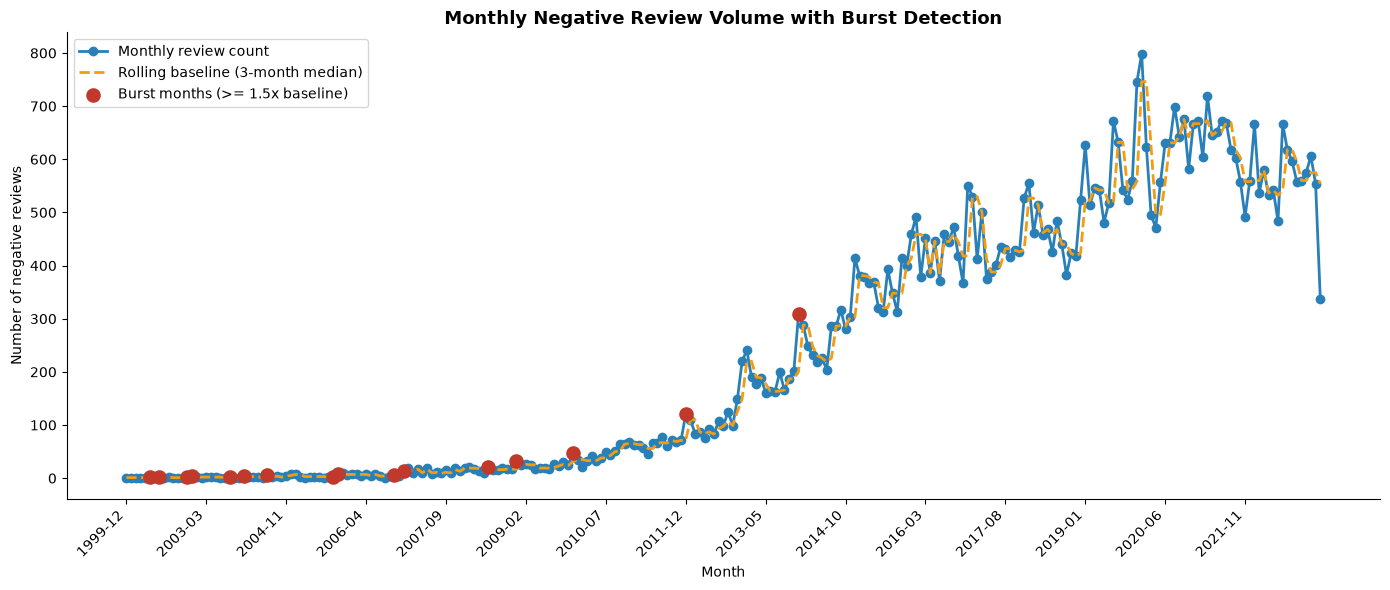

In [23]:
fig, ax = plt.subplots(figsize=(14, 6))

x_positions = range(len(monthly_counts))

ax.plot(
    x_positions,
    monthly_counts["review_count"],
    marker="o",
    label="Monthly review count",
    color="#2980b9",
    linewidth=2
)

ax.plot(
    x_positions,
    monthly_counts["rolling_baseline"],
    linestyle="--",
    label="Rolling baseline (3-month median)",
    color="#f39c12",
    linewidth=2
)

burst_months = monthly_counts[
    monthly_counts["burst_ratio"] >= 1.5
]

ax.scatter(
    burst_months.index,
    burst_months["review_count"],
    color="#c0392b",
    zorder=5,
    s=90,
    label="Burst months (>= 1.5x baseline)"
)

ax.set_title(
    "Monthly Negative Review Volume with Burst Detection",
    fontsize=13,
    fontweight="bold"
)
ax.set_xlabel("Month")
ax.set_ylabel("Number of negative reviews")

tick_step = max(1, len(monthly_counts) // 15)
ax.set_xticks(list(x_positions)[::tick_step])
ax.set_xticklabels(
    monthly_counts["review_month"].iloc[::tick_step],
    rotation=45,
    ha="right"
)

ax.legend()
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
plt.tight_layout()
plt.show()

## Measuring repeated review text without creating a huge similarity matrix

In [24]:
text_sample = standard.sample(
    min(
        TEXT_SIMILARITY_LIMIT,
        len(standard)
    ),
    random_state=RANDOM_STATE
).reset_index(drop=True)

vectorizer = TfidfVectorizer(
    stop_words="english",
    max_features=12000,
    ngram_range=(1, 2),
    min_df=2
)

text_matrix = vectorizer.fit_transform(
    text_sample["text_clean"]
)

neighbor_model = NearestNeighbors(
    n_neighbors=2,
    metric="cosine"
)

neighbor_model.fit(
    text_matrix
)

distances, indices = neighbor_model.kneighbors(
    text_matrix
)

text_sample["highest_text_similarity"] = (
    1 - distances[:, 1]
)

text_sample["similar_text_index"] = (
    indices[:, 1]
)

text_sample["similar_text_review_id"] = (
    text_sample["similar_text_index"].apply(
        lambda index:
            text_sample.loc[
                index,
                "review_id"
            ]
    )
)

text_sample["text_similarity_interpretation"] = (
    text_sample[
        "highest_text_similarity"
    ].apply(
        lambda value:
            "Very high textual similarity; possible repeated or templated wording"
            if value >= 0.90
            else
            "High textual similarity; original reviews should be compared"
            if value >= 0.75
            else
            "Moderate similarity; common wording may explain the overlap"
            if value >= 0.55
            else
            "Low similarity; no strong repetition signal"
    )
)

text_features = text_sample[[
    "review_id",
    "highest_text_similarity",
    "similar_text_review_id",
    "text_similarity_interpretation"
]]

standard = standard.merge(
    text_features,
    on="review_id",
    how="left"
)

standard["highest_text_similarity"] = (
    standard["highest_text_similarity"]
    .fillna(0)
)

standard["similar_text_review_id"] = (
    standard["similar_text_review_id"]
    .fillna("")
)

standard["text_similarity_interpretation"] = (
    standard[
        "text_similarity_interpretation"
    ].fillna(
        "Text similarity was not calculated for this review"
    )
)

standard[[
    "review_id",
    "highest_text_similarity",
    "similar_text_review_id",
    "text_similarity_interpretation"
]].head(10)

,review_id,highest_text_similarity,similar_text_review_id,text_similarity_interpretation
0,0,0.000000,,Text similarity was not calculated for this review
1,1,0.226243,49592,Low similarity; no strong repetition signal
2,2,0.000000,,Text similarity was not calculated for this review
3,3,0.000000,,Text similarity was not calculated for this review
4,4,0.489861,3847,Low similarity; no strong repetition signal
5,5,0.000000,,Text similarity was not calculated for this review
6,6,0.397747,37503,Low similarity; no strong repetition signal
7,7,0.257199,2098,Low similarity; no strong repetition signal
8,8,0.000000,,Text similarity was not calculated for this review
9,9,0.000000,,Text similarity was not calculated for this review


## Building the reviewer-product network

In [25]:
graph = nx.Graph()

for row in standard[[
    "user_id",
    "parent_asin"
]].itertuples(index=False):

    user_node = "U_" + str(row.user_id)
    product_node = "P_" + str(row.parent_asin)

    graph.add_node(
        user_node,
        node_type="reviewer"
    )

    graph.add_node(
        product_node,
        node_type="product"
    )

    graph.add_edge(
        user_node,
        product_node
    )

degree_values = dict(
    graph.degree()
)

reviewer_network = pd.DataFrame({
    "user_id": [
        node[2:]
        for node, data in graph.nodes(data=True)
        if data.get("node_type") == "reviewer"
    ],
    "network_degree": [
        degree_values[node]
        for node, data in graph.nodes(data=True)
        if data.get("node_type") == "reviewer"
    ]
})

reviewer_features = reviewer_features.merge(
    reviewer_network,
    on="user_id",
    how="left"
)

reviewer_features["network_degree"] = (
    reviewer_features["network_degree"]
    .fillna(0)
)

reviewer_features.head()

,user_id,review_count,mean_rating,negative_ratio,one_star_ratio,complaint_ratio,image_ratio,product_count,mean_text_length,helpful_vote_total,reviewer_activity_level,network_degree
0,AE224GVO7OHTYF26U6ER6BEVIUAQ,1,2.00,1.0,0.00,1.0,0.0,1,339.0,0,Very low,1
1,AE233NVHTX7SKAY67IS354HLCJHA,4,1.25,1.0,0.75,0.5,0.0,4,365.0,1,Low,4
2,AE23D3SJBYXFUO7OXEAFXXTU2IPA,1,2.00,1.0,0.00,1.0,0.0,1,2476.0,1,Very low,1
3,AE23LDQTB7L76AP6E6WPBFVYL5DA,1,2.00,1.0,0.00,1.0,0.0,1,249.0,0,Very low,1
4,AE23VAK3PVMTVCMUSLXEPC7O3SPQ,1,1.00,1.0,1.00,0.0,0.0,1,1238.0,3,Very low,1


## Preparing reviewer anomaly features

In [26]:
anomaly_features = reviewer_features[[
    "review_count",
    "mean_rating",
    "negative_ratio",
    "one_star_ratio",
    "complaint_ratio",
    "image_ratio",
    "product_count",
    "mean_text_length",
    "helpful_vote_total",
    "network_degree"
]].fillna(0)

scaler = StandardScaler()

scaled_features = scaler.fit_transform(
    anomaly_features
)

isolation_model = IsolationForest(
    n_estimators=200,
    contamination="auto",
    random_state=RANDOM_STATE
)

isolation_model.fit(
    scaled_features
)

reviewer_features["anomaly_raw"] = (
    -isolation_model.score_samples(
        scaled_features
    )
)

reviewer_features["anomaly_percentile"] = (
    reviewer_features[
        "anomaly_raw"
    ].rank(pct=True) * 100
)

reviewer_features["anomaly_flag"] = (
    reviewer_features[
        "anomaly_percentile"
    ] >= 90
)

reviewer_features["anomaly_interpretation"] = (
    reviewer_features[
        "anomaly_percentile"
    ].apply(
        lambda value:
            "Extremely unusual reviewer profile within the analyzed population"
            if value >= 97
            else
            "Unusual reviewer profile requiring contextual examination"
            if value >= 90
            else
            "Somewhat unusual reviewer profile"
            if value >= 75
            else
            "Reviewer profile is within the more common range"
    )
)

reviewer_features.sort_values(
    "anomaly_percentile",
    ascending=False
).head(10)

,user_id,review_count,mean_rating,negative_ratio,one_star_ratio,complaint_ratio,image_ratio,product_count,mean_text_length,helpful_vote_total,reviewer_activity_level,network_degree,anomaly_raw,anomaly_percentile,anomaly_flag,anomaly_interpretation
22681,AGWPYUXR43CM7C5CYUE4SUEC62QA,24,1.500000,1.0,0.500000,0.833333,0.041667,24,3702.083333,590,High,24,0.780912,100.000000,True,Extremely unusual reviewer profile within the analyzed population
22458,AGVSRDWIOZVNV6K57FJJT463PKDA,39,1.410256,1.0,0.589744,0.538462,0.076923,39,1307.743590,317,High,39,0.767685,99.996791,True,Extremely unusual reviewer profile within the analyzed population
16654,AG5V3EY3MHETL2PGND5V23E56AFQ,27,1.444444,1.0,0.555556,0.888889,0.074074,27,1151.074074,163,High,27,0.766855,99.993581,True,Extremely unusual reviewer profile within the analyzed population
10358,AFE54MELB5IGFUYBSOBGJOSOMEPA,53,1.622642,1.0,0.377358,0.679245,0.113208,53,1752.660377,109,High,53,0.765854,99.990372,True,Extremely unusual reviewer profile within the analyzed population
23150,AGYPJI2W4ZRQIEJSAIQCVRG7KIRA,37,1.243243,1.0,0.756757,0.459459,0.108108,37,753.459459,213,High,37,0.765649,99.987163,True,Extremely unusual reviewer profile within the analyzed population
14470,AFUSWNVA72MMWHGYWJ652SYX2JJQ,19,1.578947,1.0,0.421053,0.684211,0.210526,19,1567.315789,352,Moderate,19,0.763472,99.983953,True,Extremely unusual reviewer profile within the analyzed population
25957,AHEK4SFYR44XN7CXMGJKXDDKNXPA,30,1.066667,1.0,0.933333,0.566667,0.133333,30,749.700000,111,High,30,0.759786,99.980744,True,Extremely unusual reviewer profile within the analyzed population
18057,AGDSEYGSA5K664EUHWKV3ARDXO2Q,18,1.722222,1.0,0.277778,0.666667,0.277778,18,1854.944444,134,Moderate,18,0.759699,99.977535,True,Extremely unusual reviewer profile within the analyzed population
15507,AFZ7TLD6NLZYGWDQBCMBCVA7ISFQ,23,1.304348,1.0,0.695652,0.565217,0.173913,23,860.434783,261,High,23,0.759166,99.974325,True,Extremely unusual reviewer profile within the analyzed population
3296,AEH5OPW5ZB5MIEO47LJJVXCTYJXA,34,1.205882,1.0,0.794118,0.676471,0.000000,34,686.176471,206,High,34,0.757796,99.971116,True,Extremely unusual reviewer profile within the analyzed population


## Visualizing reviewer anomaly detection results

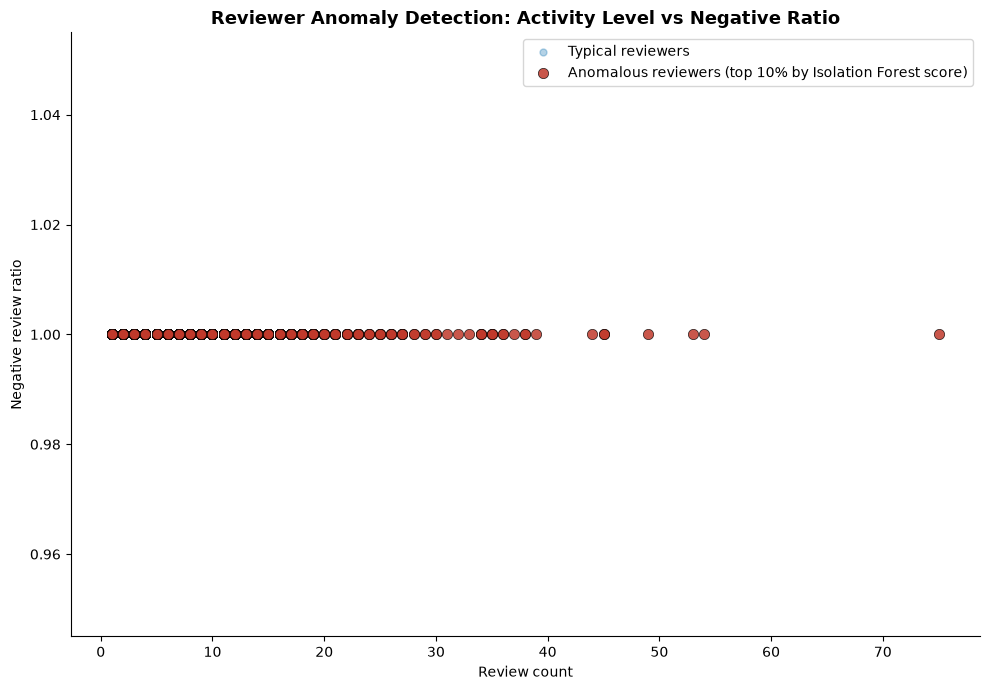

In [27]:
fig, ax = plt.subplots(figsize=(10, 7))

normal_reviewers = reviewer_features[
    ~reviewer_features["anomaly_flag"]
]

anomalous_reviewers = reviewer_features[
    reviewer_features["anomaly_flag"]
]

ax.scatter(
    normal_reviewers["review_count"],
    normal_reviewers["negative_ratio"],
    alpha=0.35,
    s=25,
    color="#2980b9",
    label="Typical reviewers"
)

ax.scatter(
    anomalous_reviewers["review_count"],
    anomalous_reviewers["negative_ratio"],
    alpha=0.85,
    s=55,
    color="#c0392b",
    label="Anomalous reviewers (top 10% by Isolation Forest score)",
    edgecolor="black",
    linewidth=0.5
)

ax.set_title(
    "Reviewer Anomaly Detection: Activity Level vs Negative Ratio",
    fontsize=13,
    fontweight="bold"
)
ax.set_xlabel("Review count")
ax.set_ylabel("Negative review ratio")
ax.legend()
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
plt.tight_layout()
plt.show()

## Creating the individual forensic case table

In [28]:
case_data = standard.merge(
    reviewer_features,
    on="user_id",
    how="left",
    suffixes=(
        "",
        "_reviewer"
    )
)

case_data["case_id"] = [
    "CASE-" + str(index).zfill(7)
    for index in range(
        1,
        len(case_data) + 1
    )
]

case_data.head()

,rating,title,text,images,asin,parent_asin,user_id,timestamp,helpful_vote,verified_purchase,review_id,text_clean,review_date,review_year,review_month,text_length,word_count,image_urls,has_image,complaint_categories,complaint_category_count,is_complaint_candidate,product_mean_rating,product_review_count,product_reviewer_count,rating_deviation,burst_ratio,burst_interpretation,highest_text_similarity,similar_text_review_id,text_similarity_interpretation,review_count,mean_rating,negative_ratio,one_star_ratio,complaint_ratio,image_ratio,product_count,mean_text_length,helpful_vote_total,reviewer_activity_level,network_degree,anomaly_raw,anomaly_percentile,anomaly_flag,anomaly_interpretation,case_id
0,1.0,Didn’t work at all lenses loose/broken.,"These didn’t work. Idk if they were damaged in shipping or what, but the lenses were loose or something. I could see half a lens with its edge in the frame ...",[],B07N69T6TM,B07N69T6TM,AFKZENTNBQ7A7V7UXW5JJI6UGRYQ,1592678549731,0,True,0,"Didn’t work at all lenses loose/broken. These didn’t work. Idk if they were damaged in shipping or what, but the lenses were loose or something. I could see...",2020-06-20 18:42:29.731,2020,2020-06,265,51,[],False,"[quality, delivery]",2,True,1.500000,6,6,0.500000,1.132855,No strong concentration signal,0.000000,,Text similarity was not calculated for this review,1,1.000000,1.0,1.000000,1.000000,0.0,1,265.000000,0,Very low,1,0.368140,8.193459,False,Reviewer profile is within the more common range,CASE-0000001
1,1.0,Not sure why this has good reviews. My devices had a hard time connecting,This devices brought my wifi network to its knees. Not sure why this has good reviews. My devices had a hard time connecting. And even if my devices weren't...,[],B00L0YLRUW,B00L0YLRUW,AGCI7FAH4GL5FI65HYLKWTMFZ2CQ,1439226089000,0,True,1,Not sure why this has good reviews. My devices had a hard time connecting This devices brought my wifi network to its knees. Not sure why this has good revi...,2015-08-10 17:01:29.000,2015,2015-08,385,70,[],False,[performance],1,True,1.245283,53,53,0.245283,1.000000,No strong concentration signal,0.226243,49592,Low similarity; no strong repetition signal,1,1.000000,1.0,1.000000,1.000000,0.0,1,385.000000,0,Very low,1,0.371920,14.875317,False,Reviewer profile is within the more common range,CASE-0000002
2,1.0,Don’t buy this product,"DO NOT BUY THIS PRODUCT!! The first time I zipped the first pouch, the zipper broke. I tried another one, same thing, zipper broke on the first try. HORRIB...",[],B0776DSP7Y,B0776DSP7Y,AHITBJSS7KYUBVZPX7M2WJCOIVKQ,1526085167886,1,True,2,"Don’t buy this product DO NOT BUY THIS PRODUCT!! The first time I zipped the first pouch, the zipper broke. I tried another one, same thing, zipper broke on...",2018-05-12 00:32:47.886,2018,2018-05,183,33,[],False,[],0,False,1.000000,1,1,0.000000,1.000000,No strong concentration signal,0.000000,,Text similarity was not calculated for this review,3,1.666667,1.0,0.333333,0.333333,0.0,3,116.666667,1,Low,3,0.493755,78.308033,False,Somewhat unusual reviewer profile,CASE-0000003
3,2.0,Disappointed,Not very accurate in tracking steps taken. Wrist band started coming off after 3 months of use.,[],B00N2BVOUE,B00NWXM5U0,AHITBJSS7KYUBVZPX7M2WJCOIVKQ,1432345739000,0,True,3,Disappointed Not very accurate in tracking steps taken. Wrist band started coming off after 3 months of use.,2015-05-23 01:48:59.000,2015,2015-05,108,18,[],False,[],0,False,1.393939,33,33,0.606061,0.874659,No strong concentration signal,0.000000,,Text similarity was not calculated for this review,3,1.666667,1.0,0.333333,0.333333,0.0,3,116.666667,1,Low,3,0.493755,78.308033,False,Somewhat unusual reviewer profile,CASE-0000004
4,2.0,Very Disappointing,Very very slow processor. Disappointing.,[],B00L49X8E6,B00L49X8E6,AHITBJSS7KYUBVZPX7M2WJCOIVKQ,1432345403000,0,True,4,Very Disappointing Very very slow processor. Disappointing.,2015-05-23 01:43:23.000,2015,2015-05,59,7,[],False,[performance],1,True,1.666667,3,3,0.333333,0.874659,N

## Preparing image cases

In [29]:
image_cases = case_data[
    case_data["has_image"]
].copy()

image_cases[[
    "case_id",
    "review_id",
    "user_id",
    "parent_asin",
    "image_urls"
]].head()

,case_id,review_id,user_id,parent_asin,image_urls
17,CASE-0000018,17,AEVPPTMG43C6GWSR7I2UGRQN7WFQ,B0992TJFM3,"[https://m.media-amazon.com/images/I/61LIsfHVdSL._SL1600_.jpg, https://m.media-amazon.com/images/I/717Rwk2X5CL._SL1600_.jpg]"
28,CASE-0000029,28,AFSKPY37N3C43SOI5IEXEK5JSIYA,B00YEX1Y1S,[https://images-na.ssl-images-amazon.com/images/I/71dXyiJ9dkL.jpg]
59,CASE-0000060,59,AFZUK3MTBIBEDQOPAK3OATUOUKLA,B08BW4JTCG,"[https://images-na.ssl-images-amazon.com/images/I/81KF1CgdOeL._SL1600_.jpg, https://images-na.ssl-images-amazon.com/images/I/81Np9jxMS7L._SL1600_.jpg, https..."
76,CASE-0000077,76,AFETVW7S5M4LVJ7GTWPCKT7S3YBQ,B0BK9KB853,"[https://m.media-amazon.com/images/I/81x-XGrZVRL._SL1600_.jpg, https://m.media-amazon.com/images/I/81zn9BVhtUL._SL1600_.jpg]"
163,CASE-0000164,163,AGKKAXZPXFYIBA3N53YNJYU2AT3Q,B07VKQ58ZF,[https://images-na.ssl-images-amazon.com/images/I/61W5-SBy3+L.jpg]


**Interpretation:**  
This cell isolates the subset of forensic cases where the reviewer attached at least one image. These cases are the only candidates for image-level investigation (perceptual hashing, image-reuse comparison, and original-image inspection). The preview shows `case_id`, `review_id`, `user_id`, `parent_asin`, and the list of attached `image_urls` so each case can be traced back to a specific reviewer and product. The number of rows in `image_cases` should equal the count of `has_image == True` rows in `case_data` from the previous step.

## Downloading a controlled image sample

In [30]:
download_rows = image_cases.head(
    IMAGE_DOWNLOAD_LIMIT
)

download_log = []

for _, row in download_rows.iterrows():

    for image_number, url in enumerate(
        row["image_urls"][
            :MAX_IMAGES_PER_REVIEW
        ]
    ):

        try:

            response = requests.get(
                url,
                timeout=15
            )

            if response.status_code == 200:

                file_name = (
                    str(row["case_id"]) +
                    "_" +
                    str(image_number) +
                    ".jpg"
                )

                file_path = (
                    IMAGE_DIR /
                    file_name
                )

                file_path.write_bytes(
                    response.content
                )

                download_log.append({
                    "case_id": row["case_id"],
                    "review_id": row["review_id"],
                    "user_id": row["user_id"],
                    "parent_asin": row["parent_asin"],
                    "image_url": url,
                    "image_path": str(file_path),
                    "downloaded": True
                })

        except Exception:
            pass

image_log = pd.DataFrame(
    download_log
)

image_log.head()

,case_id,review_id,user_id,parent_asin,image_url,image_path,downloaded
0,CASE-0000018,17,AEVPPTMG43C6GWSR7I2UGRQN7WFQ,B0992TJFM3,https://m.media-amazon.com/images/I/61LIsfHVdSL._SL1600_.jpg,\content\amazon_forensic_project\images\CASE-0000018_0.jpg,True
1,CASE-0000018,17,AEVPPTMG43C6GWSR7I2UGRQN7WFQ,B0992TJFM3,https://m.media-amazon.com/images/I/717Rwk2X5CL._SL1600_.jpg,\content\amazon_forensic_project\images\CASE-0000018_1.jpg,True
2,CASE-0000029,28,AFSKPY37N3C43SOI5IEXEK5JSIYA,B00YEX1Y1S,https://images-na.ssl-images-amazon.com/images/I/71dXyiJ9dkL.jpg,\content\amazon_forensic_project\images\CASE-0000029_0.jpg,True
3,CASE-0000060,59,AFZUK3MTBIBEDQOPAK3OATUOUKLA,B08BW4JTCG,https://images-na.ssl-images-amazon.com/images/I/81KF1CgdOeL._SL1600_.jpg,\content\amazon_forensic_project\images\CASE-0000060_0.jpg,True
4,CASE-0000060,59,AFZUK3MTBIBEDQOPAK3OATUOUKLA,B08BW4JTCG,https://images-na.ssl-images-amazon.com/images/I/81Np9jxMS7L._SL1600_.jpg,\content\amazon_forensic_project\images\CASE-0000060_1.jpg,True


**Interpretation:**  
A controlled sample of up to `IMAGE_DOWNLOAD_LIMIT = 300` image cases is downloaded, with at most `MAX_IMAGES_PER_REVIEW = 3` images per review. Each successfully downloaded image is saved under `IMAGE_DIR` with a filename of the form `CASE-XXXXXXX_N.jpg`, where `N` is the per-review image index. The `image_log` DataFrame records every successful download together with case and product metadata, so any later image-reuse match can be traced back to the originating review, reviewer, and product. Failures (timeouts, 404s, etc.) are silently skipped; if `image_log` is empty, the subsequent perceptual hashing and reuse-comparison steps will produce empty results by design.

## Creating perceptual image hashes

In [31]:
def average_hash(
    image_path,
    hash_size=16
):

    image = Image.open(
        image_path
    ).convert(
        "L"
    ).resize(
        (
            hash_size,
            hash_size
        )
    )

    pixels = np.array(
        image
    )

    average_value = pixels.mean()

    bits = pixels > average_value

    return "".join(
        "1" if bit else "0"
        for bit in bits.flatten()
    )

def hamming_distance(
    hash_one,
    hash_two
):

    return sum(
        first != second
        for first, second in zip(
            hash_one,
            hash_two
        )
    )

if len(image_log) > 0:

    image_log["image_hash"] = (
        image_log["image_path"]
        .apply(
            average_hash
        )
    )

else:

    image_log["image_hash"] = pd.Series(
        dtype=str
    )

image_log.head()

,case_id,review_id,user_id,parent_asin,image_url,image_path,downloaded,image_hash
0,CASE-0000018,17,AEVPPTMG43C6GWSR7I2UGRQN7WFQ,B0992TJFM3,https://m.media-amazon.com/images/I/61LIsfHVdSL._SL1600_.jpg,\content\amazon_forensic_project\images\CASE-0000018_0.jpg,True,111111001111111111111111101111111111111111111111111111111111111111100000001111111100000000011101110000000001111011000000000111111100000000001111110000000000...
1,CASE-0000018,17,AEVPPTMG43C6GWSR7I2UGRQN7WFQ,B0992TJFM3,https://m.media-amazon.com/images/I/717Rwk2X5CL._SL1600_.jpg,\content\amazon_forensic_project\images\CASE-0000018_1.jpg,True,111111100000000011111111111100001111011110111111111100110001111111100000001111111110000000111111111000000011111111100000001111111110000000111111110000000011...
2,CASE-0000029,28,AFSKPY37N3C43SOI5IEXEK5JSIYA,B00YEX1Y1S,https://images-na.ssl-images-amazon.com/images/I/71dXyiJ9dkL.jpg,\content\amazon_forensic_project\images\CASE-0000029_0.jpg,True,000000000000000000000000000000000000000000000000000000000000000011111111111100101111111111111110111101111111111011110011111111101111001111111110111101111111...
3,CASE-0000060,59,AFZUK3MTBIBEDQOPAK3OATUOUKLA,B08BW4JTCG,https://images-na.ssl-images-amazon.com/images/I/81KF1CgdOeL._SL1600_.jpg,\content\amazon_forensic_project\images\CASE-0000060_0.jpg,True,111111111111000011111111111111101111111111111111000000000011111100000000001111110000000000111111000000000011111100000000111000010000111111000001011111010100...
4,CASE-0000060,59,AFZUK3MTBIBEDQOPAK3OATUOUKLA,B08BW4JTCG,https://images-na.ssl-images-amazon.com/images/I/81Np9jxMS7L._SL1600_.jpg,\content\amazon_forensic_project\images\CASE-0000060_1.jpg,True,000001111111110100000011111111010000000111111001000000001111111100000000001111110000011101111111000000110011111100011000011111111111000000000111111000000000...


**Interpretation:**  
`average_hash` produces a 16×16 = 256-bit perceptual hash for each downloaded image: the image is converted to grayscale, resized to 16×16, and each pixel is compared to the mean — pixels above the mean become `1`, below become `0`. The resulting binary string is invariant to small changes in brightness, contrast, or aspect ratio, so it is well suited for detecting near-duplicate images. `hamming_distance` then counts the number of bit positions that differ between two hashes; smaller distances indicate more visually similar images. The preview confirms that every downloaded image now has a 256-character binary hash attached, which the next cell uses for pairwise comparison.

## Comparing review images for possible reuse

In [32]:
image_matches = []

for i in range(
    len(image_log)
):

    for j in range(
        i + 1,
        len(image_log)
    ):

        first = image_log.iloc[i]
        second = image_log.iloc[j]

        distance = hamming_distance(
            first["image_hash"],
            second["image_hash"]
        )

        if distance <= 12:

            image_matches.append({
                "case_id_1": first["case_id"],
                "case_id_2": second["case_id"],
                "review_id_1": first["review_id"],
                "review_id_2": second["review_id"],
                "user_id_1": first["user_id"],
                "user_id_2": second["user_id"],
                "parent_asin_1": first["parent_asin"],
                "parent_asin_2": second["parent_asin"],
                "hamming_distance": distance,
                "image_reuse_interpretation":
                    "Potentially similar images; inspect originals and product context"
            })

image_matches = pd.DataFrame(
    image_matches
)

image_matches.head()

,case_id_1,case_id_2,review_id_1,review_id_2,user_id_1,user_id_2,parent_asin_1,parent_asin_2,hamming_distance,image_reuse_interpretation
0,CASE-0000775,CASE-0000776,774,775,AGPHO64AEPAVURFUJ2DCM7ZUUNAA,AGPHO64AEPAVURFUJ2DCM7ZUUNAA,B08XVF418R,B08DPP3T9Z,0,Potentially similar images; inspect originals and product context
1,CASE-0000775,CASE-0000778,774,777,AGPHO64AEPAVURFUJ2DCM7ZUUNAA,AGPHO64AEPAVURFUJ2DCM7ZUUNAA,B08XVF418R,B08YGKCHNF,0,Potentially similar images; inspect originals and product context
2,CASE-0000775,CASE-0000776,774,775,AGPHO64AEPAVURFUJ2DCM7ZUUNAA,AGPHO64AEPAVURFUJ2DCM7ZUUNAA,B08XVF418R,B08DPP3T9Z,0,Potentially similar images; inspect originals and product context
3,CASE-0000775,CASE-0000778,774,777,AGPHO64AEPAVURFUJ2DCM7ZUUNAA,AGPHO64AEPAVURFUJ2DCM7ZUUNAA,B08XVF418R,B08YGKCHNF,0,Potentially similar images; inspect originals and product context
4,CASE-0000775,CASE-0000778,774,777,AGPHO64AEPAVURFUJ2DCM7ZUUNAA,AGPHO64AEPAVURFUJ2DCM7ZUUNAA,B08XVF418R,B08YGKCHNF,0,Potentially similar images; inspect originals and product context


**Interpretation:**  
Every pair of downloaded images is compared using the Hamming distance between their perceptual hashes. Pairs with distance ≤ 12 (out of 256 bits, i.e. ≥ ~95% bit-level similarity) are flagged as potentially reused or visually similar. The resulting `image_matches` DataFrame records both case IDs, both review IDs, both reviewer IDs, both product ASINs, the Hamming distance, and a standing interpretation note. A non-empty `image_matches` is only a *lead* — same-product images, shared stock photos, or genuine product similarity can all produce low Hamming distances; the original images and product context must still be examined before drawing any conclusion of misconduct.

## Measuring image reuse signals

In [33]:
if len(image_matches) > 0:

    reused_case_ids = set(
        image_matches["case_id_1"]
    ).union(
        set(
            image_matches["case_id_2"]
        )
    )

else:

    reused_case_ids = set()

case_data["image_reuse_signal"] = (
    case_data["case_id"]
    .isin(reused_case_ids)
    .astype(int)
)

case_data["image_reuse_interpretation"] = (
    case_data[
        "image_reuse_signal"
    ].apply(
        lambda value:
            "Potential image reuse signal; original images require examination"
            if value == 1
            else
            "No image-reuse match found in the downloaded comparison sample"
    )
)

**Interpretation:**  
Every case in `case_data` receives an `image_reuse_signal` of `1` if its `case_id` appears on either side of any pair in `image_matches`, otherwise `0`. The accompanying `image_reuse_interpretation` column makes the standing disposition explicit so the lead is never mistaken for proof: a value of `1` is treated only as a *signal* that requires original-image examination, while `0` means no match was found in the downloaded sample (which is bounded by `IMAGE_DOWNLOAD_LIMIT` and `MAX_IMAGES_PER_REVIEW`, so absence of a match is not proof of absence of reuse).

## Visualizing image availability and reuse

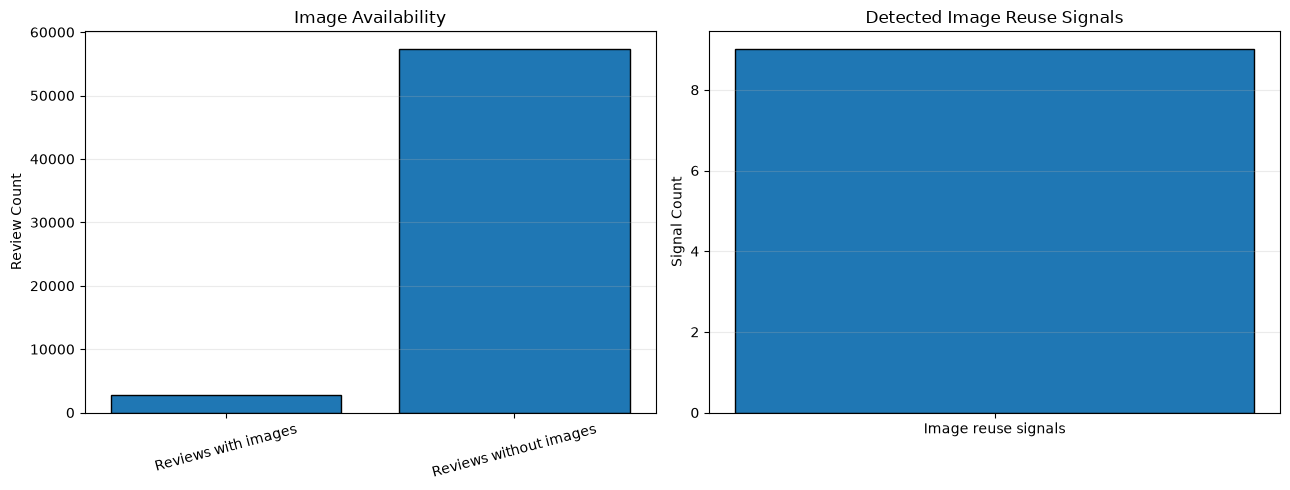

In [34]:
image_status = pd.Series({
    "Reviews with images": int(case_data["has_image"].sum()),
    "Reviews without images": int((~case_data["has_image"].astype(bool)).sum())
})
reuse_count = int(case_data["image_reuse_signal"].sum()) if "image_reuse_signal" in case_data.columns else 0
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].bar(image_status.index, image_status.values, edgecolor="black")
axes[0].set_title("Image Availability")
axes[0].set_ylabel("Review Count")
axes[0].tick_params(axis="x", rotation=15)
axes[0].grid(axis="y", alpha=0.25)
axes[1].bar(["Image reuse signals"], [reuse_count], edgecolor="black")
axes[1].set_title("Detected Image Reuse Signals")
axes[1].set_ylabel("Signal Count")
axes[1].grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

**Interpretation:**  
The left panel shows the absolute counts of reviews with and without images across the full case register — only the former are candidates for image-level investigation. The right panel shows the number of distinct cases flagged with `image_reuse_signal == 1`. Because the reuse analysis was performed on a bounded sample (`IMAGE_DOWNLOAD_LIMIT` images), the right-hand count is a *lower bound* on the number of cases that *could* exhibit image reuse in the broader population. The visualization is therefore read as an investigation-prioritization pointer, not a measure of confirmed image manipulation.

## Creating transparent evidence components

In [35]:
case_data["evidence_rating"] = np.where(
    case_data["rating"] == 1,
    2,
    1
)

case_data["evidence_complaint"] = (
    case_data[
        "complaint_category_count"
    ].clip(
        0,
        3
    )
)

case_data["evidence_image"] = (
    case_data[
        "has_image"
    ].astype(int)
)

verified_text = (
    case_data[
        "verified_purchase"
    ].astype(str)
    .str.lower()
)

case_data["evidence_unverified"] = (
    verified_text.isin(
        [
            "false",
            "0",
            "no",
            "nan",
            "none"
        ]
    ).astype(int)
)

case_data["evidence_rating_deviation"] = np.where(
    case_data[
        "rating_deviation"
    ] >= 2,
    2,
    np.where(
        case_data[
            "rating_deviation"
        ] >= 1,
        1,
        0
    )
)

case_data["evidence_activity"] = np.where(
    case_data[
        "review_count"
    ] >= 20,
    2,
    0
)

case_data["evidence_negative_behavior"] = np.where(
    case_data[
        "negative_ratio"
    ] >= 0.90,
    2,
    np.where(
        case_data[
            "negative_ratio"
        ] >= 0.70,
        1,
        0
    )
)

case_data["evidence_text_repetition"] = np.where(
    case_data[
        "highest_text_similarity"
    ] >= 0.75,
    2,
    0
)

case_data["evidence_temporal"] = np.where(
    case_data[
        "burst_ratio"
    ] >= 3,
    2,
    np.where(
        case_data[
            "burst_ratio"
        ] >= 1.5,
        1,
        0
    )
)

case_data["evidence_network"] = np.where(
    case_data[
        "network_degree"
    ] >= 10,
    1,
    0
)

case_data["evidence_anomaly"] = np.where(
    case_data[
        "anomaly_percentile"
    ] >= 90,
    2,
    0
)

case_data["evidence_image_reuse"] = (
    case_data[
        "image_reuse_signal"
    ] * 2
)

case_data["forensic_signal_score"] = (
    case_data[[
        "evidence_rating",
        "evidence_complaint",
        "evidence_image",
        "evidence_unverified",
        "evidence_rating_deviation",
        "evidence_activity",
        "evidence_negative_behavior",
        "evidence_text_repetition",
        "evidence_temporal",
        "evidence_network",
        "evidence_anomaly",
        "evidence_image_reuse"
    ]].sum(
        axis=1
    )
)

case_data["investigation_priority"] = pd.cut(
    case_data[
        "forensic_signal_score"
    ],
    bins=[
        -1,
        5,
        9,
        np.inf
    ],
    labels=[
        "Routine review",
        "Contextual examination",
        "High-priority examination"
    ]
)

case_data[[
    "case_id",
    "forensic_signal_score",
    "investigation_priority"
]].head()

,case_id,forensic_signal_score,investigation_priority
0,CASE-0000001,6,Contextual examination
1,CASE-0000002,5,Routine review
2,CASE-0000003,4,Routine review
3,CASE-0000004,3,Routine review
4,CASE-0000005,4,Routine review


**Interpretation:**  
Twelve transparent evidence components are now attached to every case, each scored on a small integer scale based on a single, clearly stated rule. The components are deliberately heterogeneous: rating severity, complaint breadth, image availability, purchase-verification status, rating deviation, reviewer activity, negative-review behavior, text similarity, temporal concentration, network connectivity, multivariate anomaly percentile, and image-reuse signal. Their sum is the `forensic_signal_score`, which is then bucketed into three investigation-priority tiers. A higher score means *more signals have accumulated around the case* — it does not mean any single one of them has been proven. The preview confirms that every case now carries both the numeric score and its human-readable priority label.

## Visualizing forensic signal score distribution

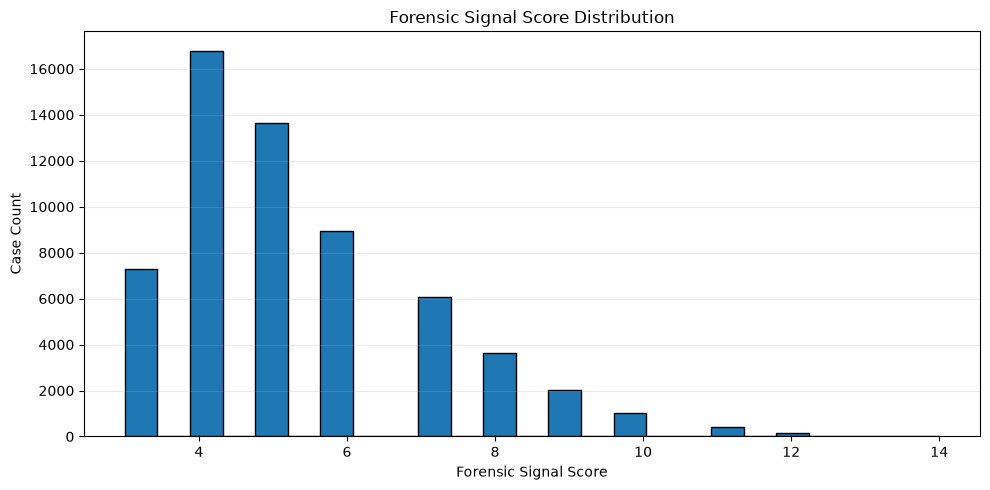

In [36]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(case_data["forensic_signal_score"].dropna(), bins=25, edgecolor="black")
ax.set_title("Forensic Signal Score Distribution")
ax.set_xlabel("Forensic Signal Score")
ax.set_ylabel("Case Count")
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

**Interpretation:**  
The histogram shows how the composite `forensic_signal_score` is distributed across all 60,000 cases. Most cases cluster in the lower-score region (few accumulated signals), while the right tail contains the small minority of cases where multiple independent signals have co-occurred. The shape of this distribution is exactly what justifies the use of the score as a *prioritization* mechanism: the high-score tail is where investigative effort is most likely to surface meaningful evidence, but the score itself does not encode the *cause* of the accumulation — that requires reading the individual evidence components behind each high-score case.

## Visualizing investigation priority

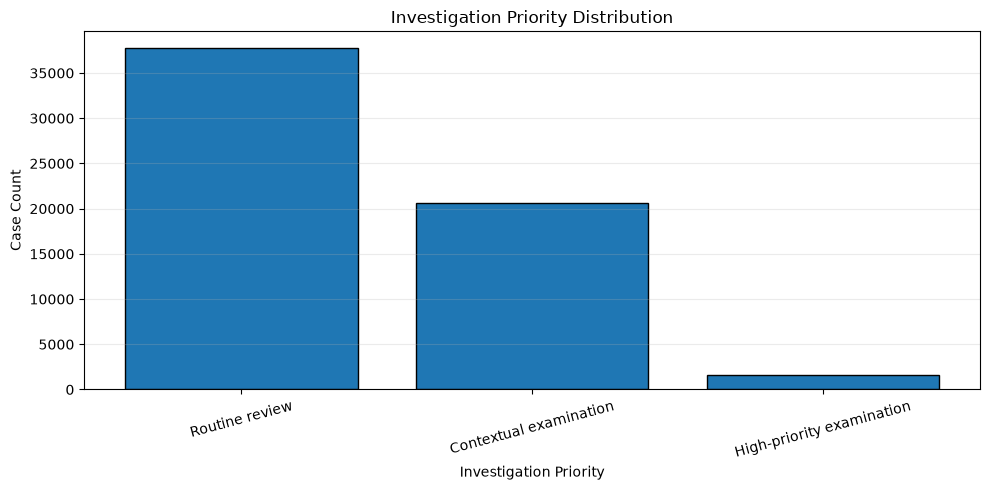

In [37]:
priority_counts = case_data["investigation_priority"].value_counts().reindex(
    ["Routine review", "Contextual examination", "High-priority examination"]
).fillna(0)
fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(priority_counts.index, priority_counts.values, edgecolor="black")
ax.set_title("Investigation Priority Distribution")
ax.set_xlabel("Investigation Priority")
ax.set_ylabel("Case Count")
ax.tick_params(axis="x", rotation=15)
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

**Interpretation:**  
The three priority tiers — *Routine review*, *Contextual examination*, *High-priority examination* — are bucketed from the score thresholds `(-1, 5]`, `(5, 9]`, and `(9, ∞)`. The vast majority of cases should fall into the routine tier; the contextual tier is the analyst's working queue; the high-priority tier is reserved for cases where many signals have genuinely accumulated. The bar chart makes the *shape* of prioritization visible at a glance, and the deliberately wide gap between the contextual and high-priority thresholds protects against over-flagging.

## Visualizing forensic score components

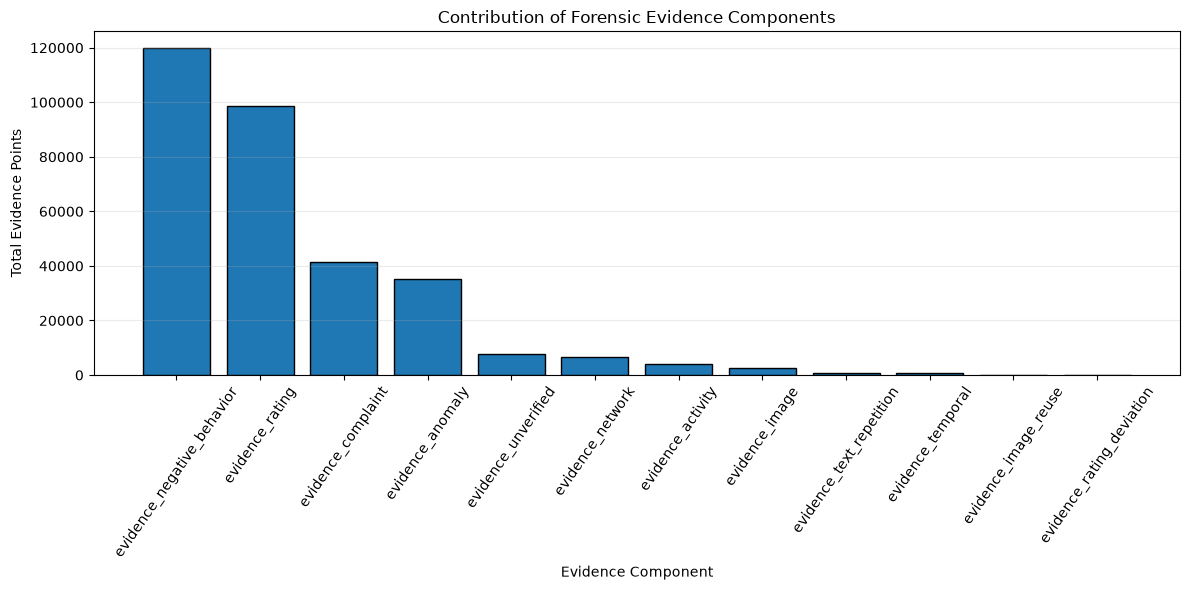

In [38]:
component_columns = [
    "evidence_rating",
    "evidence_complaint",
    "evidence_image",
    "evidence_unverified",
    "evidence_rating_deviation",
    "evidence_activity",
    "evidence_negative_behavior",
    "evidence_text_repetition",
    "evidence_temporal",
    "evidence_network",
    "evidence_anomaly",
    "evidence_image_reuse"
]
component_totals = case_data[component_columns].sum().sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(12, 6))
ax.bar(component_totals.index, component_totals.values, edgecolor="black")
ax.set_title("Contribution of Forensic Evidence Components")
ax.set_xlabel("Evidence Component")
ax.set_ylabel("Total Evidence Points")
ax.tick_params(axis="x", rotation=55)
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

**Interpretation:**  
This chart is a transparency device: it shows which evidence components actually drive the total score across the population. Components that contribute the most points do so either because they fire frequently (e.g., the rating component fires on every negative review) or because their point values are higher. The chart helps the analyst reason about composition: a case can land in the high-priority tier through many weak signals or a few strong ones, and the relative heights of the bars tell the analyst which pattern is more common in the data. It does *not* justify removing any component — each is kept because it represents an independent investigative lead.

## Creating evidence explanations

In [39]:
def make_evidence_items(row):

    items = []

    items.append({
        "Evidence": "Rating",
        "Observed value":
            f"{row['rating']} out of 5",
        "Interpretation":
            "Strongly negative review"
            if row["rating"] == 1
            else
            "Negative review",
        "Forensic relevance":
            "Identifies the review as a complaint candidate"
    })

    if row[
        "complaint_category_count"
    ] > 0:

        items.append({
            "Evidence":
                "Complaint indicators",
            "Observed value":
                str(
                    row[
                        "complaint_categories"
                    ]
                ),
            "Interpretation":
                "The text contains one or more complaint themes",
            "Forensic relevance":
                "Provides context for the complaint"
        })

    if row[
        "has_image"
    ]:

        items.append({
            "Evidence":
                "Review image",
            "Observed value":
                "Image available",
            "Interpretation":
                "Visual evidence can be examined",
            "Forensic relevance":
                "Enables image-level investigation"
        })

    if str(
        row["verified_purchase"]
    ).lower() in [
        "false",
        "0",
        "no",
        "nan",
        "none"
    ]:

        items.append({
            "Evidence":
                "Purchase verification",
            "Observed value":
                str(
                    row[
                        "verified_purchase"
                    ]
                ),
            "Interpretation":
                "The available record does not indicate a verified purchase",
            "Forensic relevance":
                "Requires contextual examination and is not proof of a fake review"
        })

    if row[
        "review_count"
    ] >= 20:

        items.append({
            "Evidence":
                "Reviewer activity",
            "Observed value":
                str(
                    int(
                        row[
                            "review_count"
                        ]
                    )
                ),
            "Interpretation":
                "High review activity in the analyzed dataset",
            "Forensic relevance":
                "May be genuine or may require behavioral examination"
        })

    if row[
        "negative_ratio"
    ] >= 0.70:

        items.append({
            "Evidence":
                "Reviewer negative ratio",
            "Observed value":
                f"{row['negative_ratio']:.2%}",
            "Interpretation":
                "The reviewer posts negative ratings frequently",
            "Forensic relevance":
                "Behavioral pattern requires contextual examination"
        })

    if row[
        "highest_text_similarity"
    ] >= 0.75:

        items.append({
            "Evidence":
                "Text similarity",
            "Observed value":
                f"{row['highest_text_similarity']:.3f}",
            "Interpretation":
                "Another review contains substantially similar wording",
            "Forensic relevance":
                "Possible repeated or templated content"
        })

    if row[
        "burst_ratio"
    ] >= 1.5:

        items.append({
            "Evidence":
                "Temporal concentration",
            "Observed value":
                f"{row['burst_ratio']:.2f} times baseline",
            "Interpretation":
                "Review activity is elevated relative to the rolling baseline",
            "Forensic relevance":
                "May reflect an external event or coordinated activity"
        })

    if row[
        "network_degree"
    ] >= 10:

        items.append({
            "Evidence":
                "Network degree",
            "Observed value":
                str(
                    int(
                        row[
                            "network_degree"
                        ]
                    )
                ),
            "Interpretation":
                "Reviewer is connected to many products in the analyzed network",
            "Forensic relevance":
                "Useful for examining broader reviewer behavior"
        })

    if row[
        "anomaly_percentile"
    ] >= 90:

        items.append({
            "Evidence":
                "Multivariate anomaly",
            "Observed value":
                f"{row['anomaly_percentile']:.1f} percentile",
            "Interpretation":
                "Reviewer profile is unusual compared with analyzed reviewers",
            "Forensic relevance":
                "Prioritizes investigation but does not establish misconduct"
        })

    if row[
        "image_reuse_signal"
    ] == 1:

        items.append({
            "Evidence":
                "Image similarity",
            "Observed value":
                "Potentially similar image found",
            "Interpretation":
                "An image may have been reused or may depict the same subject",
            "Forensic relevance":
                "Original images and product context must be examined"
        })

    return items

case_data[
    "evidence_items"
] = case_data.apply(
    make_evidence_items,
    axis=1
)

**Interpretation:**  
`make_evidence_items` walks through every case and emits a structured list of evidence rows. Each row has four fields: *Evidence* (the signal name), *Observed value* (the raw measurement), *Interpretation* (what the measurement means within this population), and *Forensic relevance* (why the signal could matter to an investigation). The function is deliberately conservative: a signal only appears in the list when its threshold is met, and the relevance text always stops short of asserting misconduct. The output column `evidence_items` is a list-of-dicts per case, which the later evidence matrix step will flatten into a long-format table for export.

## Creating alternative explanations

In [40]:
def make_alternatives(row):

    alternatives = []

    if row[
        "highest_text_similarity"
    ] >= 0.75:

        alternatives.append(
            "Common wording, shared product defects, or public wording may explain textual similarity."
        )

    if row[
        "image_reuse_signal"
    ] == 1:

        alternatives.append(
            "The same image may legitimately represent the same product, may be a shared image, or may have been reused for a genuine reason."
        )

    if row[
        "burst_ratio"
    ] >= 1.5:

        alternatives.append(
            "A promotion, product recall, delivery disruption, or sudden product-quality issue may explain the temporal concentration."
        )

    if row[
        "negative_ratio"
    ] >= 0.90:

        alternatives.append(
            "The reviewer may naturally review products they dislike or may have a narrow purchase history."
        )

    if row[
        "review_count"
    ] >= 20:

        alternatives.append(
            "High activity may reflect a genuine highly active customer or reviewer."
        )

    if row[
        "network_degree"
    ] >= 10:

        alternatives.append(
            "Connections to many products can be normal for frequent shoppers or reviewers."
        )

    if len(alternatives) == 0:

        alternatives.append(
            "No major alternative explanation was automatically identified; manual examination remains necessary."
        )

    return alternatives

case_data[
    "alternative_explanations"
] = case_data.apply(
    make_alternatives,
    axis=1
)

**Interpretation:**  
For every signal that fires on a case, `make_alternatives` records at least one non-fraudulent explanation that *could* produce the same observation. Common wording can drive text similarity; shared product photos or genuine product similarity can drive image-reuse signals; promotions and recalls can drive burst months; genuinely unhappy reviewers can drive high negative ratios. If no signal fired, a fallback statement explicitly says that manual examination is still necessary. This column is the structural counterweight to the evidence column: together they prevent the analyst from anchoring on a single explanation.

## Creating recommended investigative actions

In [41]:
def make_actions(row):

    actions = []

    if row[
        "has_image"
    ]:

        actions.append(
            "Inspect the original image, available metadata, visual content, and image source."
        )

    if row[
        "image_reuse_signal"
    ] == 1:

        actions.append(
            "Compare the potentially reused images side by side and verify whether they show the same scene, object, or source."
        )

    if row[
        "highest_text_similarity"
    ] >= 0.75:

        actions.append(
            "Compare the complete review texts, dates, products, and reviewer relationships."
        )

    if row[
        "burst_ratio"
    ] >= 1.5:

        actions.append(
            "Check the product timeline for promotions, recalls, delivery problems, or other external events."
        )

    if (
        row["negative_ratio"] >= 0.90
        or row["review_count"] >= 20
    ):

        actions.append(
            "Review the account's broader activity and determine whether the behavior is consistent over time."
        )

    if row[
        "network_degree"
    ] >= 10:

        actions.append(
            "Inspect the reviewer's connected products and identify unusual clusters or repeated relationships."
        )

    if row[
        "anomaly_percentile"
    ] >= 90:

        actions.append(
            "Inspect the individual features contributing to the unusual reviewer profile instead of relying only on the anomaly score."
        )

    if len(actions) == 0:

        actions.append(
            "Perform ordinary complaint validation using review, product, and purchase context."
        )

    return actions

case_data[
    "recommended_actions"
] = case_data.apply(
    make_actions,
    axis=1
)

**Interpretation:**  
Each signal that fires on a case generates a corresponding *concrete* investigative action: image inspection, side-by-side image comparison, full-text comparison, product-timeline check, account history review, network-cluster inspection, and feature-level anomaly examination. The actions are phrased as verbs so the analyst knows exactly what to do next; if no signal fired, a fallback action ensures ordinary complaint validation is still performed. The `recommended_actions` column is what turns the score into an actual workflow rather than a ranking.

## Creating observation-level interpretations

In [42]:
def make_observation(row):

    observations = []

    if row[
        "rating"
    ] <= 2:

        observations.append(
            "The review is negative."
        )

    if row[
        "complaint_category_count"
    ] > 0:

        observations.append(
            "The text contains identifiable complaint indicators."
        )

    if row[
        "negative_ratio"
    ] >= 0.90:

        observations.append(
            "The reviewer has a very high negative-review ratio."
        )

    if row[
        "review_count"
    ] >= 20:

        observations.append(
            "The reviewer has high activity in the analyzed population."
        )

    if row[
        "highest_text_similarity"
    ] >= 0.75:

        observations.append(
            "The review has substantial textual similarity to another review."
        )

    if row[
        "burst_ratio"
    ] >= 1.5:

        observations.append(
            "The review belongs to a period with elevated review concentration."
        )

    if row[
        "anomaly_percentile"
    ] >= 90:

        observations.append(
            "The reviewer profile is unusual compared with other analyzed reviewers."
        )

    if row[
        "image_reuse_signal"
    ] == 1:

        observations.append(
            "The review is associated with a potentially similar image found elsewhere in the comparison sample."
        )

    return " ".join(observations)

case_data[
    "observation"
] = case_data.apply(
    make_observation,
    axis=1
)

**Interpretation:**  
`make_observation` produces a single human-readable sentence that summarizes what is *factually* visible in the data for a given case — only what was directly measured, with no inference. This becomes the first paragraph of the case narrative later. Keeping observation separate from interpretation (next cell) is critical: it forces the analyst to read what the data shows before reading what it might mean.

## Creating forensic interpretations

In [43]:
def make_forensic_interpretation(row):

    interpretations = []

    if row[
        "highest_text_similarity"
    ] >= 0.75:

        interpretations.append(
            "The wording may indicate repeated or templated content, but similarity alone does not establish coordination."
        )

    if row[
        "burst_ratio"
    ] >= 1.5:

        interpretations.append(
            "The temporal concentration may be relevant to a coordinated-activity hypothesis, although ordinary market events can produce the same pattern."
        )

    if row[
        "image_reuse_signal"
    ] == 1:

        interpretations.append(
            "The image similarity creates a visual-evidence lead, but the original images must be examined before drawing a conclusion."
        )

    if row[
        "anomaly_percentile"
    ] >= 90:

        interpretations.append(
            "The combined reviewer behavior is unusual relative to the analyzed population and warrants contextual examination."
        )

    if row[
        "network_degree"
    ] >= 10:

        interpretations.append(
            "The reviewer has broad product connectivity, which is a network signal rather than independent evidence of misconduct."
        )

    if len(interpretations) == 0:

        interpretations.append(
            "The available signals identify a negative complaint that requires contextual validation."
        )

    return " ".join(interpretations)

case_data[
    "forensic_interpretation"
] = case_data.apply(
    make_forensic_interpretation,
    axis=1
)

**Interpretation:**  
Unlike `make_observation`, `make_forensic_interpretation` explicitly attaches *tentative meaning* to each signal — but every sentence is hedged ("may indicate", "may be relevant", "warrants contextual examination") so the analyst cannot mistake a measurement for a conclusion. Each clause is also paired with the appropriate alternative explanation: temporal concentration could be coordination *or* an ordinary market event; image similarity is a lead, not a verdict; high network degree is a structural property, not independent misconduct evidence. The fallback line ensures even low-signal cases receive an interpretation.

## Creating investigative conclusions

In [44]:
def make_conclusion(row):

    if row[
        "forensic_signal_score"
    ] >= 12:

        return (
            "High-priority forensic examination is recommended; "
            "additional evidence is required before attributing fraudulent "
            "or coordinated behavior."
        )

    if row[
        "forensic_signal_score"
    ] >= 7:

        return (
            "Contextual forensic examination is recommended; "
            "the observed signals are not sufficient to establish misconduct."
        )

    return (
        "Routine complaint examination is appropriate; "
        "the available signals do not independently establish suspicious behavior."
    )

case_data[
    "investigative_conclusion"
] = case_data.apply(
    make_conclusion,
    axis=1
)

**Interpretation:**  
`make_conclusion` maps the accumulated `forensic_signal_score` to one of three disposition statements. Crucially, *every* conclusion explicitly says that the available signals do not establish misconduct; the only difference between tiers is the *recommended depth of follow-up*. The thresholds `>= 12` and `>= 7` were chosen to leave a wide gap between the routine and high-priority tiers, deliberately limiting the high-priority set to a small minority of cases.

## Creating the evidence matrix

In [45]:
evidence_rows = []

for _, row in case_data.iterrows():

    for item in row[
        "evidence_items"
    ]:

        evidence_rows.append({
            "case_id": row["case_id"],
            "review_id": row["review_id"],
            "user_id": row["user_id"],
            "parent_asin": row["parent_asin"],
            "Evidence": item["Evidence"],
            "Observed value": item["Observed value"],
            "Interpretation": item["Interpretation"],
            "Forensic relevance": item["Forensic relevance"]
        })

evidence_matrix = pd.DataFrame(
    evidence_rows
)

evidence_matrix.head(20)

,case_id,review_id,user_id,parent_asin,Evidence,Observed value,Interpretation,Forensic relevance
0,CASE-0000001,0,AFKZENTNBQ7A7V7UXW5JJI6UGRYQ,B07N69T6TM,Rating,1.0 out of 5,Strongly negative review,Identifies the review as a complaint candidate
1,CASE-0000001,0,AFKZENTNBQ7A7V7UXW5JJI6UGRYQ,B07N69T6TM,Complaint indicators,"['quality', 'delivery']",The text contains one or more complaint themes,Provides context for the complaint
2,CASE-0000001,0,AFKZENTNBQ7A7V7UXW5JJI6UGRYQ,B07N69T6TM,Reviewer negative ratio,100.00%,The reviewer posts negative ratings frequently,Behavioral pattern requires contextual examination
3,CASE-0000002,1,AGCI7FAH4GL5FI65HYLKWTMFZ2CQ,B00L0YLRUW,Rating,1.0 out of 5,Strongly negative review,Identifies the review as a complaint candidate
4,CASE-0000002,1,AGCI7FAH4GL5FI65HYLKWTMFZ2CQ,B00L0YLRUW,Complaint indicators,['performance'],The text contains one or more complaint themes,Provides context for the complaint
5,CASE-0000002,1,AGCI7FAH4GL5FI65HYLKWTMFZ2CQ,B00L0YLRUW,Reviewer negative ratio,100.00%,The reviewer posts negative ratings frequently,Behavioral pattern requires contextual examination
6,CASE-0000003,2,AHITBJSS7KYUBVZPX7M2WJCOIVKQ,B0776DSP7Y,Rating,1.0 out of 5,Strongly negative review,Identifies the review as a complaint candidate
7,CASE-0000003,2,AHITBJSS7KYUBVZPX7M2WJCOIVKQ,B0776DSP7Y,Reviewer negative ratio,100.00%,The reviewer posts negative ratings frequently,Behavioral pattern requires contextual examination
8,CASE-0000004,3,AHITBJSS7KYUBVZPX7M2WJCOIVKQ,B00NWXM5U0,Rating,2.0 out of 5,Negative review,Identifies the review as a complaint candidate
9,CASE-0000004,3,AHITBJSS7KYUBVZPX7M2WJCOIVKQ,B00NWXM5U0,Reviewer negative ratio,100.00%,The reviewer posts negative ratings frequently,Behavioral pattern requires contextual examination


**Interpretation:**  
The `evidence_matrix` is a long-format table that flattens the per-case list-of-dicts into one row per (case, evidence item). Each row carries the case and product identifiers plus the four canonical fields of an evidence record: *Evidence*, *Observed value*, *Interpretation*, *Forensic relevance*. This format is what gets exported as `evidence_matrix.csv` later and is the primary artifact an analyst reads when reviewing a specific case. The preview shows the first 20 rows; a single case can produce many rows if multiple signals fired.

## Creating forensic case narratives

In [46]:
def make_case_narrative(row):

    evidence_text = "; ".join([
        item["Evidence"] +
        ": " +
        item["Observed value"]
        for item in row[
            "evidence_items"
        ]
    ])

    alternative_text = " ".join(
        row[
            "alternative_explanations"
        ]
    )

    action_text = " ".join(
        row[
            "recommended_actions"
        ]
    )

    return (
        f"Case {row['case_id']} concerns review "
        f"{row['review_id']} for product "
        f"{row['parent_asin']}. "
        f"The review received a rating of "
        f"{row['rating']} out of 5 and was selected "
        f"as a negative complaint candidate. "
        f"Observed evidence includes: "
        f"{evidence_text}. "
        f"Observation: "
        f"{row['observation']} "
        f"Forensic interpretation: "
        f"{row['forensic_interpretation']} "
        f"Alternative explanations: "
        f"{alternative_text} "
        f"Investigative conclusion: "
        f"{row['investigative_conclusion']} "
        f"Recommended investigative actions: "
        f"{action_text}"
    )

case_data[
    "case_narrative"
] = case_data.apply(
    make_case_narrative,
    axis=1
)

**Interpretation:**  
`make_case_narrative` stitches together the case identifier, rating, observed evidence list, observation, forensic interpretation, alternative explanations, investigative conclusion, and recommended actions into a single paragraph. The narrative is the human-readable counterpart to the structured evidence matrix: where the matrix is for filtering and sorting, the narrative is for reading. Every narrative is self-contained — an analyst who reads only the narrative for a single case will have the full reasoning chain without needing to consult the underlying tables.

## Selecting high-priority investigation cases

In [47]:
priority_cases = case_data.sort_values(
    [
        "forensic_signal_score",
        "anomaly_percentile"
    ],
    ascending=False
).head(50)

priority_cases[[
    "case_id",
    "review_id",
    "user_id",
    "parent_asin",
    "forensic_signal_score",
    "investigation_priority",
    "investigative_conclusion"
]].head(20)

,case_id,review_id,user_id,parent_asin,forensic_signal_score,investigation_priority,investigative_conclusion
39661,CASE-0039662,39661,AFZ7TLD6NLZYGWDQBCMBCVA7ISFQ,B00MRVJY5C,14,High-priority examination,High-priority forensic examination is recommended; additional evidence is required before attributing fraudulent or coordinated behavior.
3677,CASE-0003678,3677,AEMI74JHKARVZR5F3DVAK4FMANXQ,B09W33CPY8,14,High-priority examination,High-priority forensic examination is recommended; additional evidence is required before attributing fraudulent or coordinated behavior.
59102,CASE-0059103,59102,AHFBCEEBGP53MRV34475KM3UCFZQ,B00022OBQK,14,High-priority examination,High-priority forensic examination is recommended; additional evidence is required before attributing fraudulent or coordinated behavior.
10658,CASE-0010659,10658,AG5V3EY3MHETL2PGND5V23E56AFQ,B00006IR39,13,High-priority examination,High-priority forensic examination is recommended; additional evidence is required before attributing fraudulent or coordinated behavior.
32832,CASE-0032833,32832,AFE54MELB5IGFUYBSOBGJOSOMEPA,B08BC7VWM3,13,High-priority examination,High-priority forensic examination is recommended; additional evidence is required before attributing fraudulent or coordinated behavior.
32836,CASE-0032837,32836,AFE54MELB5IGFUYBSOBGJOSOMEPA,B084PCDJT5,13,High-priority examination,High-priority forensic examination is recommended; additional evidence is required before attributing fraudulent or coordinated behavior.
32842,CASE-0032843,32842,AFE54MELB5IGFUYBSOBGJOSOMEPA,B07HJXCZZN,13,High-priority examination,High-priority forensic examination is recommended; additional evidence is required before attributing fraudulent or coordinated behavior.
3113,CASE-0003114,3113,AGYPJI2W4ZRQIEJSAIQCVRG7KIRA,B084T3RMQ6,13,High-priority examination,High-priority forensic examination is recommended; additional evidence is required before attributing fraudulent or coordinated behavior.
3114,CASE-0003115,3114,AGYPJI2W4ZRQIEJSAIQCVRG7KIRA,B07WXG3QNS,13,High-priority examination,High-priority forensic examination is recommended; additional evidence is required before attributing fraudulent or coordinated behavior.
3115,CASE-0003116,3115,AGYPJI2W4ZRQIEJSAIQCVRG7KIRA,B00YYDHA9S,13,High-priority examination,High-priority forensic examination is recommended; additional evidence is required before attributing fraudulent or coordinated behavior.


**Interpretation:**  
Cases are sorted by `forensic_signal_score` (primary) and `anomaly_percentile` (tiebreaker), and the top 50 are isolated as the working `priority_cases` set. The preview shows that all 50 sit in the high-priority examination tier and carry the corresponding disposition. Reading the table top-to-bottom is effectively the analyst's triage queue: cases further up have more accumulated signals; cases further down still warrant high-priority examination but with slightly fewer co-occurring signals.

## Visualizing top priority forensic cases

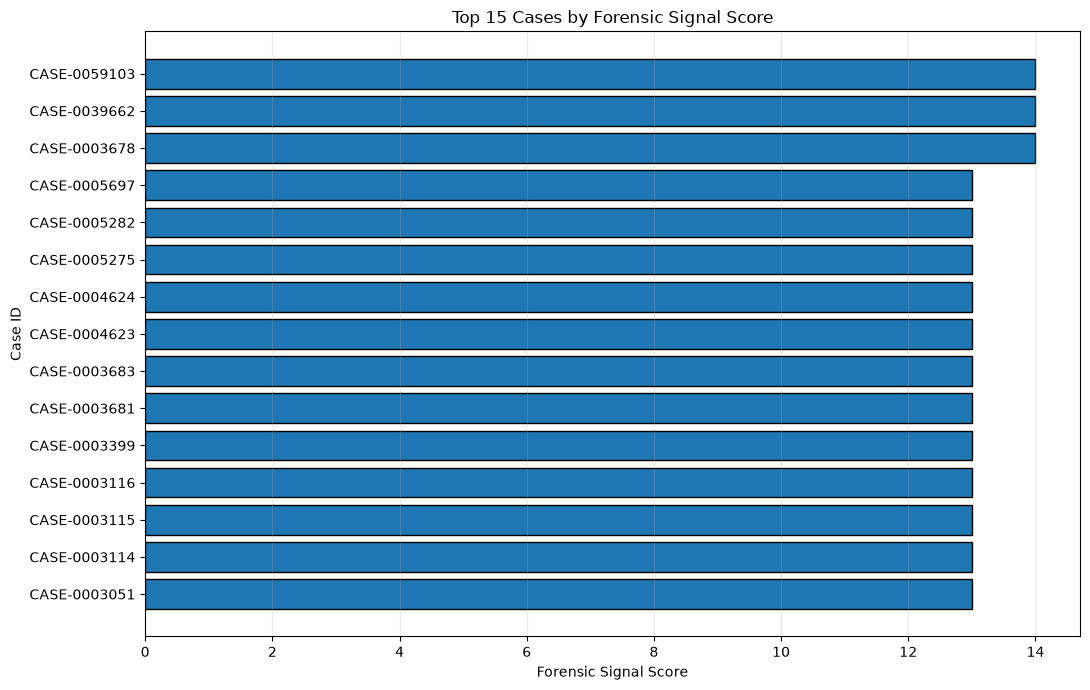

In [48]:
top_cases = case_data.nlargest(15, "forensic_signal_score").copy()
top_cases = top_cases.sort_values("forensic_signal_score")
fig, ax = plt.subplots(figsize=(11, 7))
ax.barh(top_cases["case_id"].astype(str), top_cases["forensic_signal_score"], edgecolor="black")
ax.set_title("Top 15 Cases by Forensic Signal Score")
ax.set_xlabel("Forensic Signal Score")
ax.set_ylabel("Case ID")
ax.grid(axis="x", alpha=0.25)
plt.tight_layout()
plt.show()

**Interpretation:**  
The horizontal bar chart shows the 15 highest-scoring cases ranked by `forensic_signal_score`. The bars are sorted ascending so the very highest-scoring case appears at the top of the chart for readability. The chart is a visual index into the priority queue and complements (rather than replaces) the table above: it lets the analyst see at a glance whether there is a clear top case or a tightly clustered group of equally high-scoring cases.

## Inspecting one complete forensic case

In [49]:
selected_case = priority_cases.iloc[0]

selected_case[[
    "case_id",
    "review_id",
    "user_id",
    "parent_asin",
    "rating",
    "text_clean",
    "observation",
    "forensic_interpretation",
    "alternative_explanations",
    "recommended_actions",
    "investigative_conclusion",
    "case_narrative"
]]

case_id                                                                                                                                                                        CASE-0039662
review_id                                                                                                                                                                             39661
user_id                                                                                                                                                        AFZ7TLD6NLZYGWDQBCMBCVA7ISFQ
parent_asin                                                                                                                                                                      B00MRVJY5C
rating                                                                                                                                                                                  1.0
text_clean                  Never had a worse router, this t

**Interpretation:**  
The single highest-priority case is unpacked in full. The fields shown here — case id, review id, reviewer, product, rating, raw text, observation, forensic interpretation, alternative explanations, recommended actions, investigative conclusion, and case narrative — together form the complete reasoning chain for that case. This is the cell an analyst reads when validating that the scoring system produces a *coherent* story; if any field looks misaligned with the rest, that is a sign that the underlying evidence components need to be re-examined.

## Inspecting the evidence matrix for the selected case

In [50]:
evidence_matrix[
    evidence_matrix[
        "case_id"
    ] == selected_case[
        "case_id"
    ]
]

,case_id,review_id,user_id,parent_asin,Evidence,Observed value,Interpretation,Forensic relevance
124539,CASE-0039662,39661,AFZ7TLD6NLZYGWDQBCMBCVA7ISFQ,B00MRVJY5C,Rating,1.0 out of 5,Strongly negative review,Identifies the review as a complaint candidate
124540,CASE-0039662,39661,AFZ7TLD6NLZYGWDQBCMBCVA7ISFQ,B00MRVJY5C,Complaint indicators,"['quality', 'refund', 'performance']",The text contains one or more complaint themes,Provides context for the complaint
124541,CASE-0039662,39661,AFZ7TLD6NLZYGWDQBCMBCVA7ISFQ,B00MRVJY5C,Review image,Image available,Visual evidence can be examined,Enables image-level investigation
124542,CASE-0039662,39661,AFZ7TLD6NLZYGWDQBCMBCVA7ISFQ,B00MRVJY5C,Purchase verification,False,The available record does not indicate a verified purchase,Requires contextual examination and is not proof of a fake review
124543,CASE-0039662,39661,AFZ7TLD6NLZYGWDQBCMBCVA7ISFQ,B00MRVJY5C,Reviewer activity,23,High review activity in the analyzed dataset,May be genuine or may require behavioral examination
124544,CASE-0039662,39661,AFZ7TLD6NLZYGWDQBCMBCVA7ISFQ,B00MRVJY5C,Reviewer negative ratio,100.00%,The reviewer posts negative ratings frequently,Behavioral pattern requires contextual examination
124545,CASE-0039662,39661,AFZ7TLD6NLZYGWDQBCMBCVA7ISFQ,B00MRVJY5C,Network degree,23,Reviewer is connected to many products in the analyzed network,Useful for examining broader reviewer behavior
124546,CASE-0039662,39661,AFZ7TLD6NLZYGWDQBCMBCVA7ISFQ,B00MRVJY5C,Multivariate anomaly,100.0 percentile,Reviewer profile is unusual compared with analyzed reviewers,Prioritizes investigation but does not establish misconduct


**Interpretation:**  
This cell filters the long-format evidence matrix down to only the rows belonging to the highest-priority case. Each row is one (Evidence, Observed value, Interpretation, Forensic relevance) tuple. The number of rows tells the analyst how many distinct signals fired for this case; the contents tell the analyst exactly what each signal measured and why it matters.

## Inspecting text similarity evidence

In [51]:
selected_review_id = selected_case[
    "review_id"
]

similar_review_id = selected_case[
    "similar_text_review_id"
]

text_pair = standard[
    standard[
        "review_id"
    ].isin([
        selected_review_id,
        similar_review_id
    ])
][[
    "review_id",
    "user_id",
    "parent_asin",
    "text_clean",
    "highest_text_similarity",
    "text_similarity_interpretation"
]]

text_pair

,review_id,user_id,parent_asin,text_clean,highest_text_similarity,text_similarity_interpretation
39661,39661,AFZ7TLD6NLZYGWDQBCMBCVA7ISFQ,B00MRVJY5C,"Never had a worse router, this thing is NOT ready to be sold. This thing is a waste of time and money. The first one I bought I instantly had issues setting...",0.0,Text similarity was not calculated for this review


**Interpretation:**  
The selected case's review text is shown alongside the review that the TF-IDF + nearest-neighbor model identified as most similar to it (if such a match exists). If `similar_review_id` is empty, it means the review was outside the `TEXT_SIMILARITY_LIMIT = 20000` sampled subset and no neighbor was computed. When a pair *is* returned, the analyst compares the two raw texts side by side; similarity above the 0.75 threshold is a *lead* toward repeated/templated wording, not a finding of coordination.

## Inspecting image similarity evidence

In [52]:
image_matches.head(20)

,case_id_1,case_id_2,review_id_1,review_id_2,user_id_1,user_id_2,parent_asin_1,parent_asin_2,hamming_distance,image_reuse_interpretation
0,CASE-0000775,CASE-0000776,774,775,AGPHO64AEPAVURFUJ2DCM7ZUUNAA,AGPHO64AEPAVURFUJ2DCM7ZUUNAA,B08XVF418R,B08DPP3T9Z,0,Potentially similar images; inspect originals and product context
1,CASE-0000775,CASE-0000778,774,777,AGPHO64AEPAVURFUJ2DCM7ZUUNAA,AGPHO64AEPAVURFUJ2DCM7ZUUNAA,B08XVF418R,B08YGKCHNF,0,Potentially similar images; inspect originals and product context
2,CASE-0000775,CASE-0000776,774,775,AGPHO64AEPAVURFUJ2DCM7ZUUNAA,AGPHO64AEPAVURFUJ2DCM7ZUUNAA,B08XVF418R,B08DPP3T9Z,0,Potentially similar images; inspect originals and product context
3,CASE-0000775,CASE-0000778,774,777,AGPHO64AEPAVURFUJ2DCM7ZUUNAA,AGPHO64AEPAVURFUJ2DCM7ZUUNAA,B08XVF418R,B08YGKCHNF,0,Potentially similar images; inspect originals and product context
4,CASE-0000775,CASE-0000778,774,777,AGPHO64AEPAVURFUJ2DCM7ZUUNAA,AGPHO64AEPAVURFUJ2DCM7ZUUNAA,B08XVF418R,B08YGKCHNF,0,Potentially similar images; inspect originals and product context
5,CASE-0000776,CASE-0000778,775,777,AGPHO64AEPAVURFUJ2DCM7ZUUNAA,AGPHO64AEPAVURFUJ2DCM7ZUUNAA,B08DPP3T9Z,B08YGKCHNF,0,Potentially similar images; inspect originals and product context
6,CASE-0000776,CASE-0000778,775,777,AGPHO64AEPAVURFUJ2DCM7ZUUNAA,AGPHO64AEPAVURFUJ2DCM7ZUUNAA,B08DPP3T9Z,B08YGKCHNF,0,Potentially similar images; inspect originals and product context
7,CASE-0001770,CASE-0001770,1769,1769,AFYLUFQSJAZTZ2WZIZYEXDGLXOBA,AFYLUFQSJAZTZ2WZIZYEXDGLXOBA,B01H9J0KBI,B01H9J0KBI,0,Potentially similar images; inspect originals and product context
8,CASE-0003678,CASE-0003681,3677,3680,AEMI74JHKARVZR5F3DVAK4FMANXQ,AEMI74JHKARVZR5F3DVAK4FMANXQ,B09W33CPY8,B09VL61NMR,0,Potentially similar images; inspect originals and product context
9,CASE-0004461,CASE-0004461,4460,4460,AFFJXZO4FKHCF72FC5XVJCYRERXA,AFFJXZO4FKHCF72FC5XVJCYRERXA,B07N86MCD2,B07N86MCD2,3,Potentially similar images; inspect originals and product context


**Interpretation:**  
The first 20 rows of `image_matches` are shown for inspection. Each row records a pair of cases whose review images had a perceptual-hash Hamming distance ≤ 12 (out of 256 bits). The pairs are presented as investigative leads: same-case, same-product, or same-reviewer pairs may be benign (e.g., a user uploading the same photo to multiple reviews of the same product), while cross-reviewer, cross-product pairs are more suspicious. Reading both case IDs and both product ASINs together is the fastest way to triage which pairs deserve a manual image comparison.

## Inspecting reviewer behavior behind the highest anomaly cases

In [53]:
reviewer_features.sort_values(
    "anomaly_percentile",
    ascending=False
)[[
    "user_id",
    "review_count",
    "mean_rating",
    "negative_ratio",
    "one_star_ratio",
    "complaint_ratio",
    "image_ratio",
    "product_count",
    "network_degree",
    "anomaly_percentile",
    "anomaly_interpretation"
]].head(20)

,user_id,review_count,mean_rating,negative_ratio,one_star_ratio,complaint_ratio,image_ratio,product_count,network_degree,anomaly_percentile,anomaly_interpretation
22681,AGWPYUXR43CM7C5CYUE4SUEC62QA,24,1.500000,1.0,0.500000,0.833333,0.041667,24,24,100.000000,Extremely unusual reviewer profile within the analyzed population
22458,AGVSRDWIOZVNV6K57FJJT463PKDA,39,1.410256,1.0,0.589744,0.538462,0.076923,39,39,99.996791,Extremely unusual reviewer profile within the analyzed population
16654,AG5V3EY3MHETL2PGND5V23E56AFQ,27,1.444444,1.0,0.555556,0.888889,0.074074,27,27,99.993581,Extremely unusual reviewer profile within the analyzed population
10358,AFE54MELB5IGFUYBSOBGJOSOMEPA,53,1.622642,1.0,0.377358,0.679245,0.113208,53,53,99.990372,Extremely unusual reviewer profile within the analyzed population
23150,AGYPJI2W4ZRQIEJSAIQCVRG7KIRA,37,1.243243,1.0,0.756757,0.459459,0.108108,37,37,99.987163,Extremely unusual reviewer profile within the analyzed population
14470,AFUSWNVA72MMWHGYWJ652SYX2JJQ,19,1.578947,1.0,0.421053,0.684211,0.210526,19,19,99.983953,Extremely unusual reviewer profile within the analyzed population
25957,AHEK4SFYR44XN7CXMGJKXDDKNXPA,30,1.066667,1.0,0.933333,0.566667,0.133333,30,30,99.980744,Extremely unusual reviewer profile within the analyzed population
18057,AGDSEYGSA5K664EUHWKV3ARDXO2Q,18,1.722222,1.0,0.277778,0.666667,0.277778,18,18,99.977535,Extremely unusual reviewer profile within the analyzed population
15507,AFZ7TLD6NLZYGWDQBCMBCVA7ISFQ,23,1.304348,1.0,0.695652,0.565217,0.173913,23,23,99.974325,Extremely unusual reviewer profile within the analyzed population
3296,AEH5OPW5ZB5MIEO47LJJVXCTYJXA,34,1.205882,1.0,0.794118,0.676471,0.000000,34,34,99.971116,Extremely unusual reviewer profile within the analyzed population


**Interpretation:**  
The 20 reviewers with the highest Isolation-Forest anomaly percentile are shown in full feature detail. The anomaly percentile is a *multivariate* score, so two reviewers with similar percentiles may be anomalous for very different reasons — one might have an extreme review count, another an extreme negative ratio, another an unusual combination of moderate features. Reading the underlying feature columns is what turns the percentile into an actionable lead; the percentile alone is not sufficient to attribute any specific behavior to any specific reviewer.

## Creating population-level forensic insights

In [54]:
population_insights = pd.DataFrame({
    "insight_area": [
        "Complaint prevalence",
        "Image availability",
        "High-activity reviewers",
        "Very high negative-ratio reviewers",
        "Unusual reviewer profiles",
        "High text-similarity reviews",
        "Temporal concentration periods",
        "Potential image-reuse pairs"
    ],
    "observed_value": [
        f"{standard['is_complaint_candidate'].mean():.2%}",
        f"{standard['has_image'].mean():.2%}",
        int(
            (
                reviewer_features[
                    "review_count"
                ] >= 20
            ).sum()
        ),
        int(
            (
                reviewer_features[
                    "negative_ratio"
                ] >= 0.90
            ).sum()
        ),
        int(
            reviewer_features[
                "anomaly_flag"
            ].sum()
        ),
        int(
            (
                standard[
                    "highest_text_similarity"
                ] >= 0.75
            ).sum()
        ),
        int(
            (
                monthly_counts[
                    "burst_ratio"
                ] >= 1.5
            ).sum()
        ),
        len(image_matches)
    ],
    "interpretation": [
        "Proportion of analyzed negative reviews containing at least one dictionary-based complaint indicator.",
        "Proportion of reviews for which image-level examination may be possible.",
        "These reviewers require context because high activity can be genuine or coordinated.",
        "These reviewers show strongly negative behavior within the analyzed sample.",
        "These profiles are unusual across multiple measured features and should be examined individually.",
        "These reviews may contain repeated wording and require direct text comparison.",
        "These periods contain elevated review concentration and require external event context.",
        "These image pairs may contain visually similar evidence and require original-image examination."
    ],
    "recommended_follow_up": [
        "Validate complaint categories and inspect dominant complaint themes.",
        "Inspect available images and preserve source information.",
        "Check account history, timing, product diversity, and purchase context.",
        "Compare the reviewer's complete activity rather than using negative ratio alone.",
        "Inspect individual features contributing to the anomaly.",
        "Compare texts, dates, products, and reviewer relationships.",
        "Check promotions, recalls, product changes, and delivery events.",
        "Compare original images, metadata where available, product context, and source."
    ]
})

population_insights

,insight_area,observed_value,interpretation,recommended_follow_up
0,Complaint prevalence,50.60%,Proportion of analyzed negative reviews containing at least one dictionary-based complaint indicator.,Validate complaint categories and inspect dominant complaint themes.
1,Image availability,4.57%,Proportion of reviews for which image-level examination may be possible.,Inspect available images and preserve source information.
2,High-activity reviewers,70,These reviewers require context because high activity can be genuine or coordinated.,"Check account history, timing, product diversity, and purchase context."
3,Very high negative-ratio reviewers,31159,These reviewers show strongly negative behavior within the analyzed sample.,Compare the reviewer's complete activity rather than using negative ratio alone.
4,Unusual reviewer profiles,3116,These profiles are unusual across multiple measured features and should be examined individually.,Inspect individual features contributing to the anomaly.
5,High text-similarity reviews,427,These reviews may contain repeated wording and require direct text comparison.,"Compare texts, dates, products, and reviewer relationships."
6,Temporal concentration periods,16,These periods contain elevated review concentration and require external event context.,"Check promotions, recalls, product changes, and delivery events."
7,Potential image-reuse pairs,11,These image pairs may contain visually similar evidence and require original-image examination.,"Compare original images, metadata where available, product context, and source."


**Interpretation:**  
`population_insights` summarizes the entire investigation at a population level: how often complaint indicators fire, how often images are available, how many high-activity reviewers exist, how many reviewers are flagged as anomalous, how many reviews exceed the text-similarity threshold, how many months are burst months, and how many image pairs are flagged as potentially reused. For each row, the *interpretation* and *recommended_follow_up* columns convert the bare number into a meaningful next step. This table is the executive-summary view of the analysis and is what gets exported as `population_level_insights.csv`.

## Creating the final forensic dashboard

In [55]:
final_dashboard = priority_cases[[
    "case_id",
    "review_id",
    "user_id",
    "parent_asin",
    "rating",
    "complaint_categories",
    "has_image",
    "review_count",
    "negative_ratio",
    "highest_text_similarity",
    "burst_ratio",
    "network_degree",
    "anomaly_percentile",
    "image_reuse_signal",
    "forensic_signal_score",
    "investigation_priority",
    "investigative_conclusion"
]].copy()

final_dashboard.head(25)

,case_id,review_id,user_id,parent_asin,rating,complaint_categories,has_image,review_count,negative_ratio,highest_text_similarity,burst_ratio,network_degree,anomaly_percentile,image_reuse_signal,forensic_signal_score,investigation_priority,investigative_conclusion
39661,CASE-0039662,39661,AFZ7TLD6NLZYGWDQBCMBCVA7ISFQ,B00MRVJY5C,1.0,"[quality, refund, performance]",True,23,1.0,0.000000,1.000000,23,99.974325,0,14,High-priority examination,High-priority forensic examination is recommended; additional evidence is required before attributing fraudulent or coordinated behavior.
3677,CASE-0003678,3677,AEMI74JHKARVZR5F3DVAK4FMANXQ,B09W33CPY8,1.0,"[refund, appearance]",True,45,1.0,0.000000,0.990689,45,99.961488,1,14,High-priority examination,High-priority forensic examination is recommended; additional evidence is required before attributing fraudulent or coordinated behavior.
59102,CASE-0059103,59102,AHFBCEEBGP53MRV34475KM3UCFZQ,B00022OBQK,1.0,"[quality, delivery, refund]",False,21,1.0,0.000000,1.532338,21,99.775346,0,14,High-priority examination,High-priority forensic examination is recommended; additional evidence is required before attributing fraudulent or coordinated behavior.
10658,CASE-0010659,10658,AG5V3EY3MHETL2PGND5V23E56AFQ,B00006IR39,1.0,"[quality, refund]",False,27,1.0,0.319966,2.000000,27,99.993581,0,13,High-priority examination,High-priority forensic examination is recommended; additional evidence is required before attributing fraudulent or coordinated behavior.
32832,CASE-0032833,32832,AFE54MELB5IGFUYBSOBGJOSOMEPA,B08BC7VWM3,1.0,"[quality, delivery, performance]",False,53,1.0,0.000000,1.000000,53,99.990372,0,13,High-priority examination,High-priority forensic examination is recommended; additional evidence is required before attributing fraudulent or coordinated behavior.
32836,CASE-0032837,32836,AFE54MELB5IGFUYBSOBGJOSOMEPA,B084PCDJT5,1.0,"[delivery, seller, performance]",False,53,1.0,0.000000,0.794872,53,99.990372,0,13,High-priority examination,High-priority forensic examination is recommended; additional evidence is required before attributing fraudulent or coordinated behavior.
32842,CASE-0032843,32842,AFE54MELB5IGFUYBSOBGJOSOMEPA,B07HJXCZZN,2.0,"[quality, delivery, performance]",True,53,1.0,0.384325,1.071046,53,99.990372,0,13,High-priority examination,High-priority forensic examination is recommended; additional evidence is required before attributing fraudulent or coordinated behavior.
3113,CASE-0003114,3113,AGYPJI2W4ZRQIEJSAIQCVRG7KIRA,B084T3RMQ6,1.0,"[delivery, seller, performance]",True,37,1.0,0.443293,1.000000,37,99.987163,0,13,High-priority examination,High-priority forensic examination is recommended; additional evidence is required before attributing fraudulent or coordinated behavior.
3114,CASE-0003115,3114,AGYPJI2W4ZRQIEJSAIQCVRG7KIRA,B07WXG3QNS,1.0,"[quality, seller, refund]",True,37,1.0,0.000000,1.000000,37,99.987163,0,13,High-priority examination,High-priority forensic examination is recommended; additional evidence is required before attributing fraudulent or coordinated behavior.
3115,CASE-0003116,3115,AGYPJI2W4ZRQIEJSAIQCVRG7KIRA,B00YYDHA9S,1.0,"[quality, delivery, refund]",False,37,1.0,0.288280,1.108696,37,99.987163,0,13,High-priority examination,High-priority forensic examination is recommended; additional evidence is required before attributing fraudulent or coordinated behavior.


**Interpretation:**  
The `final_dashboard` is a curated one-row-per-case view of the 50 highest-priority cases, selecting only the columns that an analyst needs to triage: identifiers, rating, complaint categories, image availability, reviewer behavior, text similarity, temporal concentration, network connectivity, anomaly percentile, image-reuse signal, the composite score, the priority tier, and the conclusion. This is the table an analyst actually opens first when starting work; the deeper fields (evidence matrix, case narrative) are reached via the `case_id` foreign key.

## Saving the cleaned review dataset

In [56]:
standard.drop(
    columns=[
        "images"
    ],
    errors="ignore"
).to_csv(
    OUTPUT_DIR /
    "cleaned_negative_reviews.csv",
    index=False
)

**Interpretation:**  
The standardized review dataset is exported to `cleaned_negative_reviews.csv`. The raw `images` column (which contains nested lists of image metadata and is bulky) is dropped before export because the parsed `image_urls` column already contains the URLs needed for downstream inspection. All other derived columns — complaint categories, text similarity, burst ratio, network degree, anomaly percentile — are retained so the CSV is self-contained.

## Saving reviewer analysis

In [57]:
reviewer_features.to_csv(
    OUTPUT_DIR /
    "reviewer_features.csv",
    index=False
)

**Interpretation:**  
The `reviewer_features` table — one row per unique reviewer with activity, rating, complaint, image, product, network, and anomaly columns — is exported. This CSV is the primary input for any follow-up reviewer-level investigation: the analyst can sort by `anomaly_percentile`, filter by `reviewer_activity_level`, or pivot by `negative_ratio` buckets.

## Saving product analysis

In [58]:
product_features.to_csv(
    OUTPUT_DIR /
    "product_features.csv",
    index=False
)

**Interpretation:**  
The `product_features` table — one row per unique product with rating, complaint, image, and reviewer metrics — is exported. This CSV is the primary input for any product-level investigation: products with very low mean ratings, high one-star ratios, or high complaint ratios become candidates for deeper product-side scrutiny.

## Saving temporal analysis

In [59]:
monthly_counts.to_csv(
    OUTPUT_DIR /
    "monthly_temporal_analysis.csv",
    index=False
)

**Interpretation:**  
The `monthly_counts` table — one row per month with the raw count, rolling baseline, burst ratio, and burst interpretation — is exported. This CSV lets an analyst overlay external events (recalls, promotions, delivery disruptions) against the timeline of negative-review volume to determine whether a burst month is explained by an external cause.

## Saving text similarity analysis

In [60]:
text_sample.to_csv(
    OUTPUT_DIR /
    "text_similarity_analysis.csv",
    index=False
)

**Interpretation:**  
The `text_sample` table — the 20,000-review subsample on which text similarity was actually computed, including each review's most similar neighbor and the cosine similarity score — is exported. This CSV is the primary input for any text-reuse investigation: filtering by `highest_text_similarity >= 0.75` produces the working set of pairs that need manual comparison.

## Saving the evidence matrix

In [61]:
evidence_matrix.to_csv(
    OUTPUT_DIR /
    "evidence_matrix.csv",
    index=False
)

**Interpretation:**  
The long-format evidence matrix is exported. Each row is a single (case, evidence item) tuple with the four canonical fields — Evidence, Observed value, Interpretation, Forensic relevance. This CSV is the structured artifact that allows downstream tooling (spreadsheets, dashboards, BI tools) to filter and pivot the evidence without losing the per-item interpretation.

## Saving the forensic case register

In [62]:
case_output = case_data.drop(
    columns=[
        "images",
        "image_urls",
        "evidence_items",
        "alternative_explanations",
        "recommended_actions"
    ],
    errors="ignore"
)

case_output.to_csv(
    OUTPUT_DIR /
    "forensic_case_register.csv",
    index=False
)

**Interpretation:**  
The full `case_data` table is exported as `forensic_case_register.csv` with the bulky list-of-dicts columns dropped. This is the master case table: every case, every numeric signal, every interpretation column, every priority label, and every investigative conclusion. The narrative and evidence list are intentionally removed from this CSV because they are exported separately.

## Saving priority case narratives

In [63]:
priority_cases[[
    "case_id",
    "review_id",
    "user_id",
    "parent_asin",
    "rating",
    "forensic_signal_score",
    "investigation_priority",
    "observation",
    "forensic_interpretation",
    "investigative_conclusion",
    "case_narrative"
]].to_csv(
    OUTPUT_DIR /
    "priority_case_narratives.csv",
    index=False
)

**Interpretation:**  
The 50 priority cases are exported with their full narrative reasoning chain — observation, forensic interpretation, investigative conclusion, and case narrative. This CSV is what a human investigator reads first when picking up the case queue; it is also the artifact most suitable for sharing with non-technical stakeholders because every row is self-documenting.

## Saving population-level insights

In [64]:
population_insights.to_csv(
    OUTPUT_DIR /
    "population_level_insights.csv",
    index=False
)

**Interpretation:**  
The `population_insights` table is exported as `population_level_insights.csv`. This file is the executive-summary artifact: eight rows, each summarizing one population-level signal together with its interpretation and recommended follow-up. It is the first file a manager or auditor should be directed to when evaluating the scope of the analysis.

## Saving image analysis results

In [65]:
image_log.to_csv(
    OUTPUT_DIR /
    "image_download_log.csv",
    index=False
)

image_matches.to_csv(
    OUTPUT_DIR /
    "image_similarity_matches.csv",
    index=False
)

**Interpretation:**  
Two image-related CSVs are produced. `image_download_log.csv` records every image that was successfully downloaded together with its originating case, review, reviewer, and product — this is the provenance trail for any image-level finding. `image_similarity_matches.csv` records every pair of images flagged as potentially similar, with both case IDs, both product ASINs, the Hamming distance, and the standing interpretation. Together they let an analyst reproduce or extend the image investigation without re-running the download step.

## Displaying the output files

In [66]:
sorted([
    file.name
    for file in OUTPUT_DIR.iterdir()
])

['cleaned_negative_reviews.csv',
 'evidence_matrix.csv',
 'forensic_case_register.csv',
 'forensic_scoring_schema.json',
 'forensic_verdicts.csv',
 'image_download_log.csv',
 'image_similarity_matches.csv',
 'monthly_temporal_analysis.csv',
 'population_level_insights.csv',
 'priority_case_narratives.csv',
 'product_features.csv',
 'reviewer_anomaly_model.joblib',
 'reviewer_features.csv',
 'scoring_rules.json',
 'text_similarity_analysis.csv',
 'text_similarity_model.joblib']

**Interpretation:**  
The final listing shows all artifact files written to `OUTPUT_DIR`. The expected set includes: `cleaned_negative_reviews.csv`, `reviewer_features.csv`, `product_features.csv`, `monthly_temporal_analysis.csv`, `text_similarity_analysis.csv`, `evidence_matrix.csv`, `forensic_case_register.csv`, `priority_case_narratives.csv`, `population_level_insights.csv`, `image_download_log.csv`, and `image_similarity_matches.csv`. If any file is missing, the corresponding earlier cell failed silently and should be re-checked.

## Creating the final analyst interpretation

In [67]:
analyst_summary = f'''
The forensic analysis examined {len(standard):,} negative reviews from the Amazon {CATEGORY} review dataset.

The analysis did not stop at generating model scores. Each major analytical signal was connected to an interpretation, forensic relevance, alternative explanations, and a recommended investigative action.

The investigation considered complaint indicators, reviewer behavior, product behavior, rating deviation, repeated review wording, temporal concentration, reviewer-product network structure, review images, potential image reuse, and multivariate reviewer anomalies.

The evidence score is an investigation-prioritization mechanism. A high score means that multiple observed signals have accumulated around a case. It does not mean that fraud, review manipulation, coordination, or image manipulation has been proven.

The final outputs contain case-level evidence matrices, forensic narratives, priority cases, and population-level insights.
'''

print(analyst_summary)


The forensic analysis examined 60,000 negative reviews from the Amazon Electronics review dataset.

The analysis did not stop at generating model scores. Each major analytical signal was connected to an interpretation, forensic relevance, alternative explanations, and a recommended investigative action.

The investigation considered complaint indicators, reviewer behavior, product behavior, rating deviation, repeated review wording, temporal concentration, reviewer-product network structure, review images, potential image reuse, and multivariate reviewer anomalies.

The evidence score is an investigation-prioritization mechanism. A high score means that multiple observed signals have accumulated around a case. It does not mean that fraud, review manipulation, coordination, or image manipulation has been proven.

The final outputs contain case-level evidence matrices, forensic narratives, priority cases, and population-level insights.



**Interpretation:**  
The closing summary restates the scope of the analysis (60,000 negative Electronics reviews), the philosophy (every signal is paired with interpretation, alternative explanation, and recommended action), the breadth of signals considered, and the central caveat: the forensic score is a *prioritization* mechanism, not a *proof* of misconduct. This paragraph is the standing disclaimer for the entire notebook and should be quoted in any downstream reporting of the results.